In [1]:
import math
import os
import random
import re
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.stats import spearmanr
from tqdm.auto import tqdm

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if all((p / d).is_dir() for d in ("kev", "data", "training"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and training/ at or above {Path.cwd()}")

# Run from `code/` and expose both `code/` and `code/kev/` on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev")):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from data.base import (
    build_long_records,
    fused_eval_context,
    group_records_by_state,
    make_grouped_view,
    make_view,
    predict_probs_grouped,
)
from data.Kriner2026 import (
    AMCE_TERMS as KRINER_AMCE_TERMS,
    KRINER2026_PERSONA_COLS,
    evaluate_kriner2026_ols,
    load_kriner2026_df,
    parse_flight_description,
)
from data.Kriner2026.stimulus import CHOICE_OPTIONS as KRINER_CHOICE_OPTIONS
from data.wu2025 import WU2025_PERSONA_COLS, load_wu2025_df
from data.wu2025.stimulus import ATTR_LOCAL, ATTR_MONEY, ATTR_PERCENT, CONJOINT_OPTIONS
from models.kev_pointer import KevPointerModel
from training import free_gpu

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Load all included Wu 2025 survey rows and filter to paired electricity-plan conjoint tasks (`plan_choice`)
t_load0 = time.perf_counter()
wu2025_df = load_wu2025_df()
plan_choice_df = wu2025_df[wu2025_df["v"] == "plan_choice"].reset_index(drop=True)
load_wu_sec = time.perf_counter() - t_load0
if len(plan_choice_df) == 0:
    raise ValueError("No plan_choice rows found in wu2025_df")

# Summarize dataset size and load time: each answered task contributes 2 option rows to OLS
display(
    pd.Series(
        {
            "wu2025_total_rows": len(wu2025_df),
            "wu2025_questions": wu2025_df["v"].nunique(),
            "plan_choice_tasks": len(plan_choice_df),
            "plan_choice_option_rows": len(plan_choice_df) * 2,
            "respondents_with_plan_choice": plan_choice_df["CASEID"].nunique(),
            "distinct_displayed_pairs": plan_choice_df["qid"].nunique(),
            "load_sec": round(load_wu_sec, 4),
        },
        name="wu2025_overview",
    ).to_frame()
)

,wu2025_overview
wu2025_total_rows,90979.0000
wu2025_questions,46.0000
plan_choice_tasks,18591.0000
plan_choice_option_rows,37182.0000
respondents_with_plan_choice,1861.0000
distinct_displayed_pairs,8212.0000
load_sec,0.2033


In [3]:
# Ordered factor levels per attribute; index 0 in each list is the OLS reference level ($105, 10%, No)
WU2025_LEVELS = {
    ATTR_MONEY: ["$105", "$110", "$115", "$120", "$125"],
    ATTR_PERCENT: ["10%", "30%", "50%", "100%"],
    ATTR_LOCAL: ["No", "Yes"],
}

# Ordered names for the 8 non-intercept AMCE coefficients matching columns 1..8 of X
WU2025_BETA_NAMES = [
    *(f"{ATTR_MONEY}: {lvl} vs $105" for lvl in WU2025_LEVELS[ATTR_MONEY][1:]),
    *(f"{ATTR_PERCENT}: {lvl} vs 10%" for lvl in WU2025_LEVELS[ATTR_PERCENT][1:]),
    *(f"{ATTR_LOCAL}: {lvl} vs No" for lvl in WU2025_LEVELS[ATTR_LOCAL][1:]),
]

# SVD relative singular-value cutoff used to verify full column rank before inverting X
OLS_SVD_RCOND = 1e-8


def parse_wu2025_plan_description(desc: str) -> dict[str, str]:
    # Attribute display order is randomized per respondent, so split into 3 `Attribute: Level` clauses
    parts = desc.split("; ")
    if len(parts) != 3:
        raise ValueError(f"Expected 3 attribute clauses, got {desc!r}")
    kv: dict[str, str] = {}
    for part in parts:
        attr, sep, level = part.partition(": ")
        if not sep:
            raise ValueError(f"Malformed attribute clause {part!r} in {desc!r}")
        # Fail fast if any attribute name or level deviates from the known experimental design
        if attr not in WU2025_LEVELS:
            raise KeyError(f"Unexpected attribute {attr!r} in {desc!r}")
        if level not in WU2025_LEVELS[attr]:
            raise ValueError(f"Unexpected level {level!r} for {attr!r}")
        kv[attr] = level
    if set(kv.keys()) != set(WU2025_LEVELS.keys()):
        raise ValueError(f"Missing attributes in {desc!r}: got {sorted(kv.keys())}")
    return kv


def encode_wu2025_x_row(desc: str) -> list[float]:
    # Convert one option's description into [1.0 (intercept), 4 bill dummies, 3 renewables-% dummies, 1 local dummy]
    parsed = parse_wu2025_plan_description(desc)
    return [
        1.0,  # col 0: constant intercept (absorbs baseline choice level, dropped after projection)
        *[1.0 if parsed[ATTR_MONEY] == lvl else 0.0 for lvl in WU2025_LEVELS[ATTR_MONEY][1:]],      # cols 1..4: $110, $115, $120, $125
        *[1.0 if parsed[ATTR_PERCENT] == lvl else 0.0 for lvl in WU2025_LEVELS[ATTR_PERCENT][1:]],  # cols 5..7: 30%, 50%, 100%
        *[1.0 if parsed[ATTR_LOCAL] == lvl else 0.0 for lvl in WU2025_LEVELS[ATTR_LOCAL][1:]],      # col 8: Yes
    ]


def build_ols_projector(X: torch.Tensor) -> torch.Tensor:
    # Build fixed linear OLS operator A of shape (K, N) mapping N option outcomes -> K non-intercept betas
    if X.ndim != 2 or X.shape[0] < X.shape[1] or X.shape[1] < 2:
        raise ValueError(f"Expected 2D full-column design matrix X with N >= P >= 2, got shape {tuple(X.shape)}")
    X64 = X.to(dtype=torch.float64)
    # Fail fast via SVD if X is rank-deficient
    svals = torch.linalg.svdvals(X64)
    if float(svals[-1]) <= OLS_SVD_RCOND * float(svals[0]):
        raise ValueError(f"Rank-deficient design matrix X: min_sval={float(svals[-1]):.3e}, max_sval={float(svals[0]):.3e}")
    # pinv(X64) computes (X^T X)^{-1} X^T via SVD without squaring the condition number; [1:] drops the intercept
    return torch.linalg.pinv(X64)[1:]


def fit_ols_betas(A: torch.Tensor, outcome: torch.Tensor) -> torch.Tensor:
    # Linear OLS projection: beta = A @ outcome (differentiable whenever `outcome` comes from model predictions)
    if outcome.ndim != 1 or outcome.shape[0] != A.shape[1]:
        raise ValueError(f"Expected 1D outcome of length {A.shape[1]}, got shape {tuple(outcome.shape)}")
    return A @ outcome.to(dtype=A.dtype)


print(f"Configured {len(WU2025_BETA_NAMES)} non-intercept OLS beta terms (+ 1 intercept = {len(WU2025_BETA_NAMES) + 1} design columns)")

Configured 8 non-intercept OLS beta terms (+ 1 intercept = 9 design columns)


In [4]:
def compute_wu2025_loss(
    task_logits: torch.Tensor,
    y_flat: torch.Tensor,
    A: torch.Tensor,
    beta_lambda: float,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    # Validate paired 2-option task logits against flattened sample option targets and sample OLS projector A
    if task_logits.ndim != 2 or task_logits.shape[1] != 2:
        raise ValueError(f"Expected (num_tasks, 2) task_logits, got shape {tuple(task_logits.shape)}")
    num_rows = task_logits.numel()
    if y_flat.shape != (num_rows,) or A.shape[1] != num_rows:
        raise ValueError(f"Shape mismatch: num_rows={num_rows}, y_flat={tuple(y_flat.shape)}, A={tuple(A.shape)}")
    if y_flat.requires_grad or A.requires_grad:
        raise ValueError("Human choice targets `y_flat` and OLS projector `A` must be fixed (requires_grad=False)")

    # 1. Per-response KL divergence KL(y || p) (= CE on one-hot choices) averaged across all tasks in the respondent sample
    log_probs = torch.log_softmax(task_logits, dim=-1)
    y_2col = y_flat.view(-1, 2)
    kl_loss = torch.nn.functional.kl_div(log_probs, y_2col, reduction="batchmean")

    # 2. When beta_lambda == 0, compute sample OLS beta MSE under no_grad for logging so backward() stays pure KL/CE
    if beta_lambda == 0.0:
        with torch.no_grad():
            pred_probs_detached = torch.softmax(task_logits.detach(), dim=-1).reshape(-1)
            beta_loss = (fit_ols_betas(A, pred_probs_detached) - fit_ols_betas(A, y_flat)).pow(2).mean()
        return kl_loss, kl_loss, beta_loss

    # 3. Differentiable sample-level OLS beta MSE loss: mean((A_sample @ pred_probs - A_sample @ y_sample)^2)
    pred_probs = torch.softmax(task_logits, dim=-1).reshape(-1)
    pred_betas = fit_ols_betas(A, pred_probs)
    human_betas = fit_ols_betas(A, y_flat)
    beta_loss = (pred_betas - human_betas).pow(2).mean()

    # 4. Combined single-pass objective over the respondent sample: choice KL loss + beta_lambda * sample OLS beta MSE
    total_loss = kl_loss + beta_lambda * beta_loss
    return total_loss, kl_loss, beta_loss


print("Defined compute_wu2025_loss(task_logits, y_flat, A, beta_lambda)")

Defined compute_wu2025_loss(task_logits, y_flat, A, beta_lambda)


In [5]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 800M backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to run jaredpalmer/kev-0.8b in bf16 train mode")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Build `jaredpalmer/kev-0.8b` with the v5 training configuration (bf16 frozen backbone + rank-64 LoRA + pointer head)
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    "jaredpalmer/kev-0.8b",
    device=device,
    lora_rank=64,
    weights_dtype="bf16",
)
kev_model.net.head.temperature = 1.0  # training uses raw uncalibrated temperature = 1.0
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

# Summarize loaded model state, parameter counts, and GPU load time
trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": "jaredpalmer/kev-0.8b",
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_800m_train_mode",
    ).to_frame()
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,kev_800m_train_mode
base_model,jaredpalmer/kev-0.8b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"43,815,424"
total_params,"796,208,448"
model_load_sec,1.713


In [6]:
# Parse (column_name, non_reference_code, term_label) directly from Kriner 2026 Table 2 `AMCE_TERMS`
KRINER_TERM_SPECS: list[tuple[str, int, str]] = []
for patsy_term, term_label in KRINER_AMCE_TERMS:
    match = re.fullmatch(r"C\((\w+)\)\[T\.(\d+)\]", patsy_term)
    if match is None:
        raise ValueError(f"Unexpected Kriner2026 AMCE term syntax: {patsy_term!r}")
    KRINER_TERM_SPECS.append((match.group(1), int(match.group(2)), term_label))
KRINER_BETA_NAMES = [label for _, _, label in KRINER_TERM_SPECS]
KRINER_EXPECTED_OPTIONS = [text for _, text in KRINER_CHOICE_OPTIONS]


def encode_kriner2026_x_row(desc: str) -> list[float]:
    # Convert one displayed flight description into [1.0 (intercept), 12 Table-2 attribute-level indicators]
    codes = parse_flight_description(desc)
    return [1.0, *[1.0 if codes[col] == level_code else 0.0 for col, level_code, _ in KRINER_TERM_SPECS]]


# Build held-out cross-experiment evaluation bundle across all 5,000 Kriner 2026 `flight_choice` tasks (1,000 respondents)
t_kriner0 = time.perf_counter()
kriner2026_df = load_kriner2026_df()
kriner_flight_df = kriner2026_df[kriner2026_df["v"] == "flight_choice"].reset_index(drop=True)
if len(kriner_flight_df) == 0:
    raise ValueError("No flight_choice rows found in kriner2026_df")

kriner2026_records = build_long_records(
    kriner_flight_df,
    persona_cols=KRINER2026_PERSONA_COLS,
    include_country=False,
    year="kriner2026",
)
kriner2026_eval_bundle = group_records_by_state(
    kriner2026_records,
    view_fn=make_view,
    name="kriner2026_flight_choice",
    valid=True,
)

# Build fixed 12 x 10,000 OLS projector `A_kriner_pop` in exact `kriner2026_eval_bundle["records"]` order
kriner_x_rows: list[list[float]] = []
kriner_y_vals: list[float] = []
for task_idx, rec in enumerate(kriner2026_eval_bundle["records"]):
    if list(rec["option_texts"]) != KRINER_EXPECTED_OPTIONS:
        raise ValueError(f"Kriner task {task_idx}: expected {KRINER_EXPECTED_OPTIONS}, got {rec['option_texts']}")
    descs = rec["option_descriptions"]
    h_dist = [float(v) for v in rec["human_dist"]]
    if descs is None or len(descs) != 2 or len(h_dist) != 2 or sorted(h_dist) != [0.0, 1.0]:
        raise ValueError(f"Kriner task {task_idx}: invalid binary forced-choice record")
    for desc, y_val in zip(descs, h_dist, strict=True):
        kriner_x_rows.append(encode_kriner2026_x_row(desc))
        kriner_y_vals.append(y_val)

X_kriner_pop = torch.tensor(kriner_x_rows, dtype=torch.float64)
y_kriner_pop = torch.tensor(kriner_y_vals, dtype=torch.float64)
A_kriner_pop = build_ols_projector(X_kriner_pop)
kriner_human_betas = fit_ols_betas(A_kriner_pop, y_kriner_pop)
if bool((kriner_human_betas == 0).any()):
    raise ValueError("Zero Kriner2026 human AMCE encountered; MAPE denominator would be undefined")

# Verify machine-precision parity against `data.Kriner2026.evaluate_kriner2026_ols` (Table 2, col. 1)
_, _ref_kriner_df = evaluate_kriner2026_ols(
    kriner2026_eval_bundle,
    [r["human_dist"] for r in kriner2026_eval_bundle["records"]],
)
_max_table2_diff = float(
    (kriner_human_betas - torch.tensor(_ref_kriner_df["human"].to_numpy(), dtype=torch.float64)).abs().max()
)
if _max_table2_diff > 1e-12:
    raise AssertionError(f"PyTorch Kriner2026 OLS differs from evaluate_kriner2026_ols by {_max_table2_diff:.3e}")
kriner_bundle_prep_sec = time.perf_counter() - t_kriner0

print(
    f"Kriner2026 eval bundle: {len(kriner2026_eval_bundle['records']):,} tasks | "
    f"{len(kriner2026_eval_bundle['packed_views']):,} packed persona states | "
    f"A_kriner_pop shape: {tuple(A_kriner_pop.shape)} | max_table2_diff: {_max_table2_diff:.2e} | "
    f"prep_sec: {kriner_bundle_prep_sec:.3f}s"
)
display(pd.Series(kriner_human_betas.numpy(), index=KRINER_BETA_NAMES, name="kriner_human_pop_beta").round(4).to_frame())

Kriner2026 eval bundle: 5,000 tasks | 990 packed persona states | A_kriner_pop shape: (12, 10000) | max_table2_diff: 1.43e-15 | prep_sec: 0.292s


,kriner_human_pop_beta
Airline: Frontier,-0.0854
Airline: Southwest,-0.0238
Airline: United,-0.0220
Fuel: Sustainable aviation fuel,0.0691
Baggage: Checked bag+carry-on,0.0561
Baggage: Personal item only,-0.1393
Space: Extra legroom,0.0653
Seat: Middle,-0.0906
Seat: Window,0.0384
Price: $275,-0.0853


In [7]:
@torch.no_grad()
def validate_kriner2026_population_ols(
    model: KevPointerModel,
    eval_bundle: dict,
    A_eval: torch.Tensor,
    y_eval: torch.Tensor,
    human_eval_betas: torch.Tensor,
    beta_names: list[str],
) -> tuple[dict[str, float], pd.DataFrame]:
    # Time full evaluation wall-clock (including LoRA fusion / CudaGraphs setup + GPU inference + OLS projection)
    torch.cuda.synchronize()
    t_eval_wall0 = time.perf_counter()

    # Switch to eval mode and fuse current LoRA deltas + CudaGraphs for shared-state inference on Kriner 2026
    was_training = model.training
    model.eval()
    free_gpu()
    try:
        with torch.autocast("cuda", dtype=torch.bfloat16), fused_eval_context(model, eval_dtype=torch.bfloat16):
            preds, stats = predict_probs_grouped(model, eval_bundle, show_progress=True, return_stats=True)
    finally:
        # Always restore training mode and release temporary graph buffers so Wu 2025 training can resume immediately
        if was_training:
            model.train()
        free_gpu()

    # Fail fast if fused_eval_context failed to restore trainable parameter state or training mode
    if model.training != was_training:
        raise AssertionError(f"Expected model.training={was_training} after validation, got {model.training}")
    if any((not p.requires_grad) or p.numel() == 0 for p in model.trainable_parameters()):
        raise AssertionError("Trainable parameters were not cleanly restored after fused_eval_context")

    # Time CPU tensor stacking, Kriner 2026 choice KL computation, and `A_kriner_pop @ pred_probs` Table-2 AMCE projection
    t_ols0 = time.perf_counter()
    num_tasks = y_eval.numel() // 2
    if len(preds) != num_tasks:
        raise ValueError(f"Expected {num_tasks} Kriner2026 task predictions, got {len(preds)}")
    pred_probs_2col = torch.from_numpy(np.stack(preds, axis=0)).to(dtype=torch.float64)
    if pred_probs_2col.shape != (num_tasks, 2):
        raise ValueError(f"Expected ({num_tasks}, 2) predicted probabilities, got {tuple(pred_probs_2col.shape)}")

    kriner_kl_loss = float(
        torch.nn.functional.kl_div(
            pred_probs_2col.clamp_min(1e-12).log(),
            y_eval.view(-1, 2),
            reduction="batchmean",
        )
    )
    model_eval_betas = fit_ols_betas(A_eval, pred_probs_2col.reshape(-1))
    beta_diff = model_eval_betas - human_eval_betas
    eval_ols_ms = (time.perf_counter() - t_ols0) * 1000.0
    eval_wall_sec = time.perf_counter() - t_eval_wall0

    # Report out-of-experiment Kriner 2026 OLS / KL metrics side-by-side with detailed evaluation timing metrics
    metrics = {
        "kriner_kl_loss": kriner_kl_loss,
        "kriner_beta_mse": float(beta_diff.pow(2).mean()),
        "kriner_beta_mae": float(beta_diff.abs().mean()),
        "kriner_beta_mape_pct": float((beta_diff.abs() / human_eval_betas.abs()).mean() * 100.0),
        "spearman_rho": float(spearmanr(model_eval_betas.numpy(), human_eval_betas.numpy()).statistic),
        "eval_prep_sec": float(stats["prep_sec"]),
        "eval_gpu_sec": float(stats["gpu_sec"]),
        "eval_ols_ms": eval_ols_ms,
        "eval_wall_sec": eval_wall_sec,
        "eval_ms_per_task": (eval_wall_sec * 1000.0) / num_tasks,
    }
    beta_df = pd.DataFrame(
        {
            "human_pop_beta": human_eval_betas.numpy(),
            "model_pop_beta": model_eval_betas.numpy(),
            "diff": beta_diff.numpy(),
            "abs_diff": beta_diff.abs().numpy(),
        },
        index=pd.Index(beta_names, name="kriner_term"),
    )
    return metrics, beta_df


# Run Step 0 out-of-experiment baseline validation on Kriner 2026 (`flight_choice`) before any Wu 2025 training
step0_val_metrics, step0_beta_df = validate_kriner2026_population_ols(
    kev_model,
    kriner2026_eval_bundle,
    A_kriner_pop,
    y_kriner_pop,
    kriner_human_betas,
    KRINER_BETA_NAMES,
)
display(pd.Series(step0_val_metrics, name="step_0_kriner2026_val").round(4).to_frame())
display(step0_beta_df.round(4))

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

,step_0_kriner2026_val
kriner_kl_loss,1.0849
kriner_beta_mse,0.0178
kriner_beta_mae,0.1143
kriner_beta_mape_pct,133.5286
spearman_rho,-0.2657
eval_prep_sec,0.0429
eval_gpu_sec,8.8182
eval_ols_ms,1.6034
eval_wall_sec,10.5349
eval_ms_per_task,2.1070


,human_pop_beta,model_pop_beta,diff,abs_diff
kriner_term,,,,
Airline: Frontier,-0.0854,0.0344,0.1198,0.1198
Airline: Southwest,-0.0238,0.0267,0.0505,0.0505
Airline: United,-0.0220,0.0010,0.0230,0.0230
Fuel: Sustainable aviation fuel,0.0691,-0.0574,-0.1265,0.1265
Baggage: Checked bag+carry-on,0.0561,-0.0435,-0.0996,0.0996
Baggage: Personal item only,-0.1393,-0.0030,0.1362,0.1362
Space: Extra legroom,0.0653,-0.0813,-0.1466,0.1466
Seat: Middle,-0.0906,-0.0057,0.0849,0.0849
Seat: Window,0.0384,0.0086,-0.0299,0.0299


In [8]:
# Snapshot all 376 untrained LoRA + pointer-head tensors on CPU so every `(sample_size, beta_lambda)` run starts identically
INIT_TRAINABLE_STATE = {
    name: param.detach().cpu().clone()
    for name, param in kev_model.named_parameters()
    if param.requires_grad
}


def reset_kev_trainable_weights(model: KevPointerModel, init_state: dict[str, torch.Tensor]) -> None:
    # Fail fast if the model's trainable parameter set changed before copying Step-0 weights back onto GPU
    current_names = {name for name, param in model.named_parameters() if param.requires_grad}
    if current_names != set(init_state.keys()):
        raise ValueError("Trainable parameter names do not match INIT_TRAINABLE_STATE snapshot")
    with torch.no_grad():
        for name, param in model.named_parameters():
            if param.requires_grad:
                param.copy_(init_state[name].to(device=param.device, dtype=param.dtype))
                param.grad = None
    model.train()
    free_gpu()


# Pre-tokenize all 1,861 respondents once, storing `enc`, `X_resp` (CPU float64), and `y_resp` (GPU float64)
# so any respondent `sample_size` can stack `X_sample` and `y_sample` on the fly without re-tokenizing
t_resp_prep0 = time.perf_counter()
wu2025_respondent_items: list[dict] = []
single_resp_full_rank_count = 0

for r_caseid, r_group in tqdm(
    plan_choice_df.groupby("CASEID", sort=False),
    total=plan_choice_df["CASEID"].nunique(),
    desc="Preparing respondents",
):
    r_df = r_group.reset_index(drop=True)
    x_rows: list[list[float]] = []
    y_vals: list[float] = []
    for t_idx, row in enumerate(r_df.itertuples(index=False)):
        # Validate every respondent task's options, descriptions, and binary one-hot choice vector
        if list(row.option_texts) != CONJOINT_OPTIONS:
            raise ValueError(f"{r_caseid} task {t_idx}: expected {CONJOINT_OPTIONS}, got {row.option_texts}")
        if row.option_descriptions is None or len(row.option_descriptions) != 2:
            raise ValueError(f"{r_caseid} task {t_idx}: expected 2 option_descriptions")
        one_hot = [float(v) for v in row.one_hot]
        if len(one_hot) != 2 or sorted(one_hot) != [0.0, 1.0]:
            raise ValueError(f"{r_caseid} task {t_idx}: invalid binary one_hot {one_hot}")
        for desc, y_val in zip(row.option_descriptions, one_hot, strict=True):
            x_rows.append(encode_wu2025_x_row(desc))
            y_vals.append(y_val)

    # Tokenize the respondent's shared persona state + choice tasks once and verify target alignment
    r_records = build_long_records(r_df, persona_cols=WU2025_PERSONA_COLS, include_country=False, year="wu2025")
    r_enc, r_targets = kev_model.prepare(make_grouped_view(r_records))
    r_X = torch.tensor(x_rows, dtype=torch.float64)
    r_y = torch.tensor(y_vals, dtype=torch.float64, device=device)
    prepared_2col = torch.stack([q["target"].to(dtype=torch.float64, device=device) for q in r_targets], dim=0)
    if not torch.equal(prepared_2col, r_y.view(-1, 2)):
        raise AssertionError(f"{r_caseid}: Kev prepared target order does not match y_resp")

    if r_X.shape[0] >= r_X.shape[1]:
        r_svals = torch.linalg.svdvals(r_X)
        if float(r_svals[-1]) > OLS_SVD_RCOND * float(r_svals[0]):
            single_resp_full_rank_count += 1

    wu2025_respondent_items.append(
        {
            "caseid": str(r_caseid),
            "num_tasks": len(r_df),
            "enc": r_enc,
            "X_resp": r_X,
            "y_resp": r_y,
        }
    )

resp_prep_sec = time.perf_counter() - t_resp_prep0
if (len(wu2025_respondent_items), single_resp_full_rank_count) != (1861, 1725):
    raise AssertionError(
        f"Unexpected respondent counts: {(len(wu2025_respondent_items), single_resp_full_rank_count)}"
    )

# Registry keyed by `(sample_size, beta_lambda)` storing full step/timing logs and population OLS trajectories
experiment_runs: dict[tuple[int, float], dict] = {}

display(
    pd.Series(
        {
            "total_respondents": len(wu2025_respondent_items),
            "single_respondent_full_rank": single_resp_full_rank_count,
            "single_respondent_rank_deficient": len(wu2025_respondent_items) - single_resp_full_rank_count,
            "snapshot_trainable_tensors": len(INIT_TRAINABLE_STATE),
            "respondent_prep_sec": round(resp_prep_sec, 3),
            "ms_per_respondent_prep": round((resp_prep_sec * 1000.0) / len(wu2025_respondent_items), 3),
        },
        name="epoch_prep_summary",
    ).to_frame()
)

Preparing respondents:   0%|          | 0/1861 [00:00<?, ?it/s]

,epoch_prep_summary
total_respondents,1861.000
single_respondent_full_rank,1725.000
single_respondent_rank_deficient,136.000
snapshot_trainable_tensors,376.000
respondent_prep_sec,7.249
ms_per_respondent_prep,3.895


In [14]:
# Shared epoch hyperparameters; each optimization step draws a sample of `sample_size` human respondents
EPOCH_SEED = 42
BASE_LR_SAMPLE_1 = 2e-5               # validated 1-respondent/step learning rate from v1


def scale_lr_for_sample_size(sample_size: int) -> float:
    # Square-root AdamW LR scaling keeps 1-epoch parameter travel invariant as `steps_per_epoch` shrinks by 1/sample_size
    if not isinstance(sample_size, int) or isinstance(sample_size, bool) or sample_size < 1:
        raise ValueError(f"sample_size must be a positive integer, got {sample_size!r}")
    return BASE_LR_SAMPLE_1 * math.sqrt(sample_size)


def split_into_chunks(items: list, chunk_size: int) -> list[list]:
    # Consecutive chunks of at most `chunk_size` items, in the original order
    chunks = []
    for start in range(0, len(items), chunk_size):
        chunks.append(items[start : start + chunk_size])
    return chunks


def predict_chunk(chunk_items: list[dict]) -> torch.Tensor:
    # Shared-prefix forward pass for one chunk of respondents -> float64 logits, one row per question, 2 columns
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits_per_respondent = kev_model.forward([it["enc"] for it in chunk_items], shared_prefix=True)
    rows = []
    for respondent_logits in logits_per_respondent:
        for question_logits in respondent_logits:
            rows.append(question_logits.to(dtype=torch.float64))
    return torch.stack(rows, dim=0)


def make_val_row(step: int, epoch: int, respondents_seen: int, train_loss: float, metrics: dict, lr: float, train_elapsed_sec: float) -> dict:
    # Validation row column order: ids, `train_loss`, Kriner metrics up to `spearman_rho`, `lr`, eval timings, `train_elapsed_sec` last
    row = {"step": step, "epoch": epoch, "respondents_seen": respondents_seen, "train_loss": train_loss}
    for key, value in metrics.items():
        row[key] = value
        if key == "spearman_rho":
            row["lr"] = lr
    row["train_elapsed_sec"] = train_elapsed_sec
    return row


def draw_live_plots(fig, axes, step_rows: list[dict], val_rows: list[dict], rolling_steps: int, steps_per_epoch: int) -> None:
    # Redraw train loss, Kriner 2026 KL / beta MSE / MAE / MAPE, and per-step LR; dashed lines mark epoch boundaries
    for ax in axes.flat:
        ax.clear()
    val_steps = [r["step"] for r in val_rows]
    if step_rows:
        train_steps = [r["step"] for r in step_rows]
        train_loss = pd.Series([r["total_loss"] for r in step_rows])
        axes[0, 0].plot(train_steps, train_loss, alpha=0.3, label="per step")
        axes[0, 0].plot(train_steps, train_loss.rolling(rolling_steps, min_periods=1).mean(), label=f"rolling {rolling_steps}")
        axes[0, 0].legend(fontsize=8)
        axes[1, 2].plot(train_steps, [r["lr"] for r in step_rows])
    for ax, key, title in [
        (axes[0, 1], "kriner_kl_loss", "Kriner KL loss"),
        (axes[0, 2], "kriner_beta_mse", "Kriner beta MSE"),
        (axes[1, 0], "kriner_beta_mae", "Kriner beta MAE"),
        (axes[1, 1], "kriner_beta_mape_pct", "Kriner beta MAPE (%)"),
    ]:
        ax.plot(val_steps, [r[key] for r in val_rows], marker="o")
        ax.set_title(title)
    axes[0, 0].set_title("Wu 2025 train total loss")
    axes[1, 2].set_title("learning rate")
    last_step = step_rows[-1]["step"] if step_rows else 0
    for ax in axes.flat:
        ax.set_xlabel("step")
        for b in range(steps_per_epoch, last_step + 1, steps_per_epoch):
            ax.axvline(b, color="gray", linestyle="--", linewidth=0.8)
    fig.tight_layout()


def run_wu2025_epoch(
    sample_size: int,
    beta_lambda: float,
    lr: float,
    num_epochs: int,
    eval_every: int,
    lr_schedule: str,
    weight_decay: float,
    micro_chunk: int,
    gradient_checkpointing: bool,
) -> dict:
    # Fail fast on invalid arguments
    if not isinstance(sample_size, int) or isinstance(sample_size, bool) or sample_size < 1:
        raise ValueError(f"sample_size must be a positive integer, got {sample_size!r}")
    if not isinstance(num_epochs, int) or isinstance(num_epochs, bool) or num_epochs < 1:
        raise ValueError(f"num_epochs must be a positive integer, got {num_epochs!r}")
    if not isinstance(eval_every, int) or isinstance(eval_every, bool) or eval_every < 1:
        raise ValueError(f"eval_every must be a positive integer, got {eval_every!r}")
    if lr_schedule not in ("onecycle", "constant"):
        raise ValueError(f"lr_schedule must be 'onecycle' or 'constant', got {lr_schedule!r}")
    if weight_decay < 0.0:
        raise ValueError(f"weight_decay must be non-negative, got {weight_decay}")
    if not isinstance(micro_chunk, int) or isinstance(micro_chunk, bool) or micro_chunk < 1:
        raise ValueError(f"micro_chunk must be a positive integer, got {micro_chunk!r}")
    if not isinstance(gradient_checkpointing, bool):
        raise ValueError(f"gradient_checkpointing must be a bool, got {gradient_checkpointing!r}")
    if beta_lambda < 0.0:
        raise ValueError(f"beta_lambda must be non-negative, got {beta_lambda}")
    if lr <= 0.0:
        raise ValueError(f"lr must be positive, got {lr}")

    t_wall0 = time.perf_counter()

    # Reset weights to exact Step-0 initialization and re-seed RNGs so respondent sample order matches across runs
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    reset_kev_trainable_weights(kev_model, INIT_TRAINABLE_STATE)
    if gradient_checkpointing:
        kev_model.enable_checkpointing()
    else:
        kev_model.net.lm.gradient_checkpointing_disable()

    rng = random.Random(EPOCH_SEED)
    torch.manual_seed(EPOCH_SEED)
    torch.cuda.manual_seed_all(EPOCH_SEED)

    # One epoch = one pass over all respondents; respondents are reshuffled at the start of every epoch
    base_items = list(wu2025_respondent_items)
    total_respondents = len(base_items)
    steps_per_epoch = math.ceil(total_respondents / sample_size)
    total_steps = steps_per_epoch * num_epochs
    postfix_every = max(1, steps_per_epoch // 60)
    rolling_steps = max(1, round(300 / sample_size))

    # Everything that allocates optimizer state or autograd graphs runs inside try/finally so GPU memory is released
    # as soon as the run ends, including on KeyboardInterrupt or an exception
    try:
        # Configure AdamW + either one OneCycleLR schedule spanning all `num_epochs * steps_per_epoch` steps or a constant LR
        trainable_params = list(kev_model.trainable_parameters())
        optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=weight_decay, fused=True)
        if lr_schedule == "onecycle" and total_steps > 1:
            scheduler = torch.optim.lr_scheduler.OneCycleLR(
                optimizer,
                max_lr=lr,
                total_steps=total_steps,
                pct_start=0.1,
                div_factor=25.0,
                final_div_factor=1e4,
            )
        else:
            scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda _: 1.0)

        step_rows: list[dict] = []
        # Step 0 has no update yet, so its `train_loss` and `lr` are NaN; later rows record the LR used by the most recent update
        val_rows: list[dict] = [make_val_row(0, 0, 0, float("nan"), step0_val_metrics, float("nan"), 0.0)]
        # One live validation table that is redrawn in place after every evaluation
        val_display = display(pd.DataFrame(val_rows).set_index("step").round(5), display_id=True)
        # One live figure redrawn in place at every progress-bar update and every evaluation
        fig, axes = plt.subplots(2, 3, figsize=(15, 7))
        plt.close(fig)
        draw_live_plots(fig, axes, step_rows, val_rows, rolling_steps, steps_per_epoch)
        plot_display = display(fig, display_id=True)
        final_beta_df = step0_beta_df
        cum_train_sec = 0.0
        cum_eval_sec = 0.0
        respondents_seen = 0

        pbar = tqdm(range(1, total_steps + 1), total=total_steps, desc=f"S={sample_size} | lambda={beta_lambda:g}")
        for step_idx in pbar:
            epoch_idx = (step_idx - 1) // steps_per_epoch + 1
            step_in_epoch = (step_idx - 1) % steps_per_epoch + 1
            if step_in_epoch == 1:
                epoch_items = list(base_items)
                rng.shuffle(epoch_items)
            start_idx = (step_in_epoch - 1) * sample_size
            sample_items = epoch_items[start_idx : start_idx + sample_size]
            n_sample_resp = len(sample_items)
            respondents_seen += n_sample_resp

            torch.cuda.synchronize()
            t_step0 = time.perf_counter()
            optimizer.zero_grad(set_to_none=True)

            # The sample is processed in micro-chunks of `micro_chunk` respondents so peak VRAM depends on the chunk size,
            # not the sample size. Two passes give exactly the gradient of one big backward over the whole sample.
            sample_chunks = split_into_chunks(sample_items, micro_chunk)

            # 1. Pass 1: forward every chunk WITHOUT an autograd graph and keep only the logits.
            #    Save the CUDA random state before each chunk so pass 2 replays the same LoRA dropout masks.
            chunk_rng_states = []
            chunk_logits_list = []
            with torch.no_grad():
                for chunk in sample_chunks:
                    chunk_rng_states.append(torch.cuda.get_rng_state())
                    chunk_logits_list.append(predict_chunk(chunk))
            task_logits = torch.cat(chunk_logits_list, dim=0)
            torch.cuda.synchronize()
            t_after_fwd = time.perf_counter()

            # 2. Full-sample loss on the pass-1 logits (sample-level OLS if rank == 9/9), then the gradient of the loss
            #    with respect to each logit. No model weights are involved in this backward.
            task_logits.requires_grad_(True)
            X_sample = torch.cat([it["X_resp"] for it in sample_items], dim=0)
            y_sample = torch.cat([it["y_resp"] for it in sample_items], dim=0)
            if X_sample.shape[0] >= X_sample.shape[1]:
                svals = torch.linalg.svdvals(X_sample)
                has_ols = float(svals[-1]) > OLS_SVD_RCOND * float(svals[0])
            else:
                has_ols = False

            if has_ols:
                A_sample = torch.linalg.pinv(X_sample)[1:].to(device=device)
                total_loss, kl_loss, beta_loss = compute_wu2025_loss(
                    task_logits,
                    y_sample,
                    A_sample,
                    beta_lambda=beta_lambda,
                )
                raw_beta_val = float(beta_loss.detach().cpu())
            else:
                A_sample = None
                beta_loss = None
                log_probs = torch.log_softmax(task_logits, dim=-1)
                kl_loss = torch.nn.functional.kl_div(log_probs, y_sample.view(-1, 2), reduction="batchmean")
                total_loss = kl_loss
                raw_beta_val = float("nan")

            kl_val = float(kl_loss.detach().cpu())
            total_val = float(total_loss.detach().cpu())
            total_loss.backward()                                   # fills task_logits.grad
            questions_per_chunk = [len(chunk_logits) for chunk_logits in chunk_logits_list]
            grad_per_chunk = task_logits.grad.split(questions_per_chunk, dim=0)
            torch.cuda.synchronize()
            t_after_loss = time.perf_counter()

            # 3. Pass 2: re-run each chunk WITH a graph (same dropout masks as pass 1) and push its share of the
            #    logit gradient into the weights; .backward() adds each chunk's contribution to every p.grad
            for chunk, rng_state, chunk_grad in zip(sample_chunks, chunk_rng_states, grad_per_chunk):
                torch.cuda.set_rng_state(rng_state)
                chunk_logits = predict_chunk(chunk)
                chunk_logits.backward(chunk_grad)
                del chunk_logits

            # 4. Gradient clipping, AdamW update, and LR schedule step (once per sample, after all chunks)
            grad_norm = torch.nn.utils.clip_grad_norm_(trainable_params, 1.0)
            if not bool(torch.isfinite(grad_norm)):
                raise FloatingPointError(f"Non-finite gradient norm {float(grad_norm)} at step {step_idx}")
            grad_norm_val = float(grad_norm.detach().cpu())
            step_lr = float(optimizer.param_groups[0]["lr"])
            optimizer.step()
            if step_idx < total_steps:
                scheduler.step()
            optimizer.zero_grad(set_to_none=True)

            # Release per-step tensors immediately so nothing lingers across steps or evaluations
            del chunk_logits_list, task_logits, grad_per_chunk, X_sample, y_sample, A_sample, total_loss, kl_loss, beta_loss
            torch.cuda.synchronize()
            t_after_bwd = time.perf_counter()

            fwd_ms = (t_after_fwd - t_step0) * 1000.0
            loss_ms = (t_after_loss - t_after_fwd) * 1000.0
            bwd_opt_ms = (t_after_bwd - t_after_loss) * 1000.0
            step_ms = (t_after_bwd - t_step0) * 1000.0
            resp_ms = step_ms / n_sample_resp
            cum_train_sec += t_after_bwd - t_step0

            step_rows.append(
                {
                    "step": step_idx,
                    "epoch": epoch_idx,
                    "num_respondents": n_sample_resp,
                    "respondents_seen": respondents_seen,
                    "has_ols": has_ols,
                    "kl_loss": kl_val,
                    "raw_beta_loss": raw_beta_val,
                    "weighted_beta_loss": beta_lambda * raw_beta_val if has_ols else 0.0,
                    "total_loss": total_val,
                    "grad_norm": grad_norm_val,
                    "lr": step_lr,
                    "fwd_ms": fwd_ms,
                    "loss_ms": loss_ms,
                    "bwd_opt_ms": bwd_opt_ms,
                    "step_ms": step_ms,
                    "ms_per_respondent": resp_ms,
                }
            )

            # Update live progress bar with rolling (~300 respondents) statistical losses and step / per-respondent timings
            if step_idx % postfix_every == 0 or step_idx == total_steps:
                recent = step_rows[-rolling_steps:]
                recent_betas = [r["raw_beta_loss"] for r in recent if r["has_ols"]]
                pbar.set_postfix(
                    kl=f"{float(np.mean([r['kl_loss'] for r in recent])):.3f}",
                    beta=f"{float(np.mean(recent_betas)):.4f}" if recent_betas else "n/a",
                    step_ms=f"{float(np.mean([r['step_ms'] for r in recent])):.1f}",
                    resp_ms=f"{float(np.mean([r['ms_per_respondent'] for r in recent])):.1f}",
                )

            # 5. Evaluate out-of-experiment Kriner 2026 population OLS every `eval_every` steps and at the final step
            if step_idx % eval_every == 0 or step_idx == total_steps:
                v_metrics, final_beta_df = validate_kriner2026_population_ols(
                    kev_model,
                    kriner2026_eval_bundle,
                    A_kriner_pop,
                    y_kriner_pop,
                    kriner_human_betas,
                    KRINER_BETA_NAMES,
                )
                cum_eval_sec += v_metrics["eval_wall_sec"]
                # Train loss for this row = mean train total loss over the steps since the previous evaluation
                previous_eval_step = val_rows[-1]["step"]
                steps_since_previous_eval = [r for r in step_rows if r["step"] > previous_eval_step]
                interval_train_loss = float(np.mean([r["total_loss"] for r in steps_since_previous_eval]))
                val_rows.append(make_val_row(step_idx, epoch_idx, respondents_seen, interval_train_loss, v_metrics, step_lr, cum_train_sec))
                val_display.update(pd.DataFrame(val_rows).set_index("step").round(5))

            # 6. Redraw live plots at every progress-bar update and right after every evaluation
            if step_idx % postfix_every == 0 or step_idx % eval_every == 0 or step_idx == total_steps:
                draw_live_plots(fig, axes, step_rows, val_rows, rolling_steps, steps_per_epoch)
                plot_display.update(fig)
    finally:
        # Drop gradients, optimizer state, and any per-step tensors still bound in this frame, then release cached CUDA blocks
        for param in kev_model.trainable_parameters():
            param.grad = None
        optimizer = scheduler = trainable_params = None
        chunk_logits_list = chunk_logits = task_logits = grad_per_chunk = None
        X_sample = y_sample = A_sample = total_loss = kl_loss = beta_loss = log_probs = svals = grad_norm = None
        free_gpu()

    total_wall_sec = time.perf_counter() - t_wall0
    step_df = pd.DataFrame(step_rows)
    val_history_df = pd.DataFrame(val_rows).set_index("step")
    ols_steps = step_df[step_df["has_ols"]]
    edge_window = max(1, round(0.15 * len(step_df)))          # first/last ~15% of all training steps regardless of sample_size
    ols_edge_window = max(1, round(0.15 * len(ols_steps)))

    # Summarize both statistical loss metrics and per-step / per-respondent / eval / wall-clock timing metrics
    summary = pd.Series(
        {
            "sample_size": sample_size,
            "beta_lambda": beta_lambda,
            "lr": lr,
            "num_epochs": num_epochs,
            "steps_per_epoch": steps_per_epoch,
            "total_steps": total_steps,
            "eval_every": eval_every,
            "lr_schedule": lr_schedule,
            "weight_decay": weight_decay,
            "micro_chunk": micro_chunk,
            "gradient_checkpointing": gradient_checkpointing,
            "rank_deficient_steps": int((~step_df["has_ols"]).sum()),
            "train_kl_first15pct": float(step_df["kl_loss"].iloc[:edge_window].mean()),
            "train_kl_last15pct": float(step_df["kl_loss"].iloc[-edge_window:].mean()),
            "train_raw_beta_first15pct": float(ols_steps["raw_beta_loss"].iloc[:ols_edge_window].mean()),
            "train_raw_beta_last15pct": float(ols_steps["raw_beta_loss"].iloc[-ols_edge_window:].mean()),
            "train_weighted_beta_last15pct": float(ols_steps["weighted_beta_loss"].iloc[-ols_edge_window:].mean()),
            "train_total_first15pct": float(step_df["total_loss"].iloc[:edge_window].mean()),
            "train_total_last15pct": float(step_df["total_loss"].iloc[-edge_window:].mean()),
            "mean_grad_norm": float(step_df["grad_norm"].mean()),
            "mean_fwd_ms": float(step_df["fwd_ms"].mean()),
            "mean_loss_ms": float(step_df["loss_ms"].mean()),
            "mean_bwd_opt_ms": float(step_df["bwd_opt_ms"].mean()),
            "mean_step_ms": float(step_df["step_ms"].mean()),
            "mean_ms_per_respondent": (cum_train_sec * 1000.0) / respondents_seen,
            "mean_eval_wall_sec": float(val_history_df["eval_wall_sec"].iloc[1:].mean()),
            "mean_eval_gpu_sec": float(val_history_df["eval_gpu_sec"].iloc[1:].mean()),
            "train_only_sec": cum_train_sec,
            "eval_only_sec": cum_eval_sec,
            "total_wall_sec": total_wall_sec,
        },
        name=f"S_{sample_size}_lambda_{beta_lambda:g}_summary",
    )
    val_display.update(val_history_df.round(5))

    return {
        "sample_size": sample_size,
        "beta_lambda": beta_lambda,
        "lr": lr,
        "num_epochs": num_epochs,
        "eval_every": eval_every,
        "lr_schedule": lr_schedule,
        "weight_decay": weight_decay,
        "micro_chunk": micro_chunk,
        "gradient_checkpointing": gradient_checkpointing,
        "summary": summary,
        "step_df": step_df,
        "val_history_df": val_history_df,
        "final_beta_df": final_beta_df,
    }


print("Defined scale_lr_for_sample_size(sample_size) and run_wu2025_epoch(sample_size, beta_lambda, lr, num_epochs, eval_every, lr_schedule, weight_decay, micro_chunk, gradient_checkpointing)")

Defined scale_lr_for_sample_size(sample_size) and run_wu2025_epoch(sample_size, beta_lambda, lr, num_epochs, eval_every, lr_schedule, weight_decay, micro_chunk, gradient_checkpointing)


# Test micro-batching

In [20]:
# Gradient check: does the two-pass method (B) give the same weight gradients as one big backward (A)?

# ---------- Settings ----------
CHECK_SAMPLE_SIZE = 64    # respondents in the sample (same as one training step)
CHUNK = 2                 # respondents per chunk
LAM = 5.0                 # beta_lambda > 0 so the OLS term is included

# ---------- Setup ----------
reset_kev_trainable_weights(kev_model, INIT_TRAINABLE_STATE)
kev_model.enable_checkpointing()          # so method A (whole sample in one graph) fits in VRAM
params = list(kev_model.trainable_parameters())

sample = wu2025_respondent_items[:CHECK_SAMPLE_SIZE]
chunks = [sample[i : i + CHUNK] for i in range(0, len(sample), CHUNK)]

X_sample = torch.cat([resp["X_resp"] for resp in sample], dim=0)
y_sample = torch.cat([resp["y_resp"] for resp in sample], dim=0)
A_sample = torch.linalg.pinv(X_sample)[1:].to(device)

# Save the random state once per chunk, so every forward pass of that chunk uses the same dropout masks
chunk_rng_states = []
for chunk in chunks:
    chunk_rng_states.append(torch.cuda.get_rng_state())


def predict_chunk_with_rng(chunk, rng_state):
    # Run the model on one chunk of respondents and return its logits: one row per question, 2 columns
    torch.cuda.set_rng_state(rng_state)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits_per_respondent = kev_model.forward([resp["enc"] for resp in chunk], shared_prefix=True)
    rows = []
    for respondent_logits in logits_per_respondent:
        for question_logits in respondent_logits:
            rows.append(question_logits.to(torch.float64))
    return torch.stack(rows, dim=0)


def collect_weight_gradients():
    # Flatten every trainable parameter's .grad into one long vector, then clear the grads
    flat = torch.cat([p.grad.flatten().float() for p in params])
    for p in params:
        p.grad = None
    return flat


# ---------- Method A: one big backward ----------
def method_a():
    # 1. Forward every chunk WITH the autograd graph kept, so the whole sample's graph is in memory
    logits_parts = []
    for chunk, rng_state in zip(chunks, chunk_rng_states):
        logits_parts.append(predict_chunk_with_rng(chunk, rng_state))
    all_logits = torch.cat(logits_parts, dim=0)

    # 2. Loss on the full sample (KL + beta_lambda * sample-OLS beta loss)
    loss, _, _ = compute_wu2025_loss(all_logits, y_sample, A_sample, beta_lambda=LAM)

    # 3. One backward through the whole sample
    loss.backward()
    return float(loss.detach()), collect_weight_gradients()


# ---------- Method B: two passes ----------
def method_b():
    # Pass 1: forward every chunk WITHOUT a graph; keep only the predictions
    logits_parts = []
    with torch.no_grad():
        for chunk, rng_state in zip(chunks, chunk_rng_states):
            logits_parts.append(predict_chunk_with_rng(chunk, rng_state))
    all_logits = torch.cat(logits_parts, dim=0)

    # In between: full-sample loss, and the gradient of the loss w.r.t. each prediction
    all_logits.requires_grad_(True)
    loss, _, _ = compute_wu2025_loss(all_logits, y_sample, A_sample, beta_lambda=LAM)
    loss.backward()                                   # fills all_logits.grad; no model weights involved yet
    questions_per_chunk = [len(part) for part in logits_parts]
    grad_per_chunk = all_logits.grad.split(questions_per_chunk, dim=0)

    # Pass 2: re-run each chunk WITH a graph and push its share of the gradient into the weights
    for chunk, rng_state, chunk_grad in zip(chunks, chunk_rng_states, grad_per_chunk):
        chunk_logits = predict_chunk_with_rng(chunk, rng_state)   # same dropout masks as pass 1
        chunk_logits.backward(chunk_grad)                # adds this chunk's contribution to every p.grad
    return float(loss.detach()), collect_weight_gradients()


# ---------- Compare ----------
def relative_difference(u, v):
    return float((u - v).norm() / u.norm())


def cosine_similarity(u, v):
    return float(torch.nn.functional.cosine_similarity(u, v, dim=0))


try:
    loss_a1, grad_a1 = method_a()
    loss_a2, grad_a2 = method_a()          # A twice: how much GPU noise alone changes the gradient
    loss_b, grad_b = method_b()

    print(f"sample={CHECK_SAMPLE_SIZE} respondents ({y_sample.numel() // 2} questions) | chunk={CHUNK} | lambda={LAM:g}")
    print(f"loss  A={loss_a1:.8f}  A again={loss_a2:.8f}  B={loss_b:.8f}")
    print(f"A vs A again (noise floor): rel={relative_difference(grad_a1, grad_a2):.2e}  cos={cosine_similarity(grad_a1, grad_a2):.8f}")
    print(f"A vs B       (two-pass):    rel={relative_difference(grad_a1, grad_b):.2e}  cos={cosine_similarity(grad_a1, grad_b):.8f}")
finally:
    for p in params:
        p.grad = None
    free_gpu()

KeyboardInterrupt: 

# Find max micro chunk


In [10]:
# Settings for the micro-chunk search (re-run this group after loading a different model)
SEARCH_GRADIENT_CHECKPOINTING = False   # search with the same setting you will train with
SEARCH_MAX_CHUNK = 64                   # largest chunk size to try


def respondent_token_count(item: dict) -> int:
    # Total tokens in one respondent's encoding (persona state + every question branch); VRAM grows with tokens
    return len(item["enc"]["ids"])


# Worst case: the chunk of size k made of the k respondents with the most tokens
respondents_by_size = sorted(wu2025_respondent_items, key=respondent_token_count, reverse=True)

largest_respondents_df = pd.DataFrame(
    {
        "caseid": [it["caseid"] for it in respondents_by_size[:10]],
        "num_tasks": [it["num_tasks"] for it in respondents_by_size[:10]],
        "tokens": [respondent_token_count(it) for it in respondents_by_size[:10]],
    }
)
display(largest_respondents_df)


,caseid,num_tasks,tokens
0,wu2025_75,10,1980
1,wu2025_1540,10,1980
2,wu2025_873,10,1979
3,wu2025_1246,10,1979
4,wu2025_1414,10,1979
5,wu2025_356,10,1978
6,wu2025_826,10,1978
7,wu2025_1641,10,1978
8,wu2025_56,10,1977
9,wu2025_123,10,1977


In [11]:
def chunk_fits(chunk_size: int) -> tuple[bool, float]:
    # One training-style pass-2 forward + backward + AdamW step on the `chunk_size` largest respondents.
    # Returns (fits in VRAM, peak allocated GiB). Weights are reset before and after, so the model is unchanged.
    worst_chunk = respondents_by_size[:chunk_size]
    reset_kev_trainable_weights(kev_model, INIT_TRAINABLE_STATE)
    torch.cuda.reset_peak_memory_stats()

    optimizer = torch.optim.AdamW(list(kev_model.trainable_parameters()), lr=1e-8, fused=True)
    chunk_logits = None
    fits = True
    try:
        chunk_logits = predict_chunk(worst_chunk)
        chunk_logits.sum().backward()
        optimizer.step()
        torch.cuda.synchronize()
    except torch.cuda.OutOfMemoryError:
        fits = False
    finally:
        chunk_logits = None
        optimizer = None
        free_gpu()

    peak_gib = torch.cuda.max_memory_allocated() / 2**30
    reset_kev_trainable_weights(kev_model, INIT_TRAINABLE_STATE)
    return fits, peak_gib


# Use the same checkpointing setting the training run will use
if SEARCH_GRADIENT_CHECKPOINTING:
    kev_model.enable_checkpointing()
else:
    kev_model.net.lm.gradient_checkpointing_disable()

total_vram_gib = torch.cuda.get_device_properties(0).total_memory / 2**30
search_rows = []
largest_fit = 0
smallest_fail = None


def record_trial(chunk_size: int, fits: bool, peak_gib: float) -> None:
    search_rows.append(
        {
            "chunk_size": chunk_size,
            "tokens": sum(respondent_token_count(it) for it in respondents_by_size[:chunk_size]),
            "fits": fits,
            "peak_gib": round(peak_gib, 2) if fits else float("nan"),
            "peak_pct_of_vram": round(100.0 * peak_gib / total_vram_gib, 1) if fits else float("nan"),
        }
    )


# Phase 1: double the chunk size (1, 2, 4, ...) until it runs out of memory or passes SEARCH_MAX_CHUNK
chunk_size = 1
while chunk_size <= SEARCH_MAX_CHUNK:
    fits, peak_gib = chunk_fits(chunk_size)
    record_trial(chunk_size, fits, peak_gib)
    if not fits:
        smallest_fail = chunk_size
        break
    largest_fit = chunk_size
    chunk_size = chunk_size * 2

# Phase 2: binary search between the largest size that fit and the smallest size that failed
if smallest_fail is not None:
    low = largest_fit
    high = smallest_fail
    while high - low > 1:
        middle = (low + high) // 2
        fits, peak_gib = chunk_fits(middle)
        record_trial(middle, fits, peak_gib)
        if fits:
            low = middle
        else:
            high = middle
    largest_fit = low

MAX_FITTING_MICRO_CHUNK = largest_fit
display(pd.DataFrame(search_rows).sort_values("chunk_size").set_index("chunk_size"))
print(
    f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | total VRAM {total_vram_gib:.1f} GiB | "
    f"MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}"
    + ("" if smallest_fail is not None else f" (no OOM up to SEARCH_MAX_CHUNK={SEARCH_MAX_CHUNK})")
)


[W1115 12:59:14.188781423 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 178257920 bytes (free: 164167680, total: 33710276608).
[W1115 12:59:14.188878423 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 178257920 bytes (free: 164167680, total: 33710276608).
[W1115 12:59:15.371443961 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 155189248 bytes (free: 267190272, total: 33710276608).
[W1115 12:59:15.410412283 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 77594624 bytes (free: 202178560, total: 33710276608).
[W1115 12:59:15.410491393 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 77594624 bytes (free: 202178560, total: 33710276608).
[W1115 12:59:16.574427366 CUDACachingAllocator.cpp:3933] memory allocation failed with 

,tokens,fits,peak_gib,peak_pct_of_vram
chunk_size,,,,
1,1980,True,7.27,23.2
2,3960,True,12.75,40.6
4,7918,True,23.68,75.4
5,9897,False,NaN,NaN
6,11875,False,NaN,NaN
8,15831,False,NaN,NaN


gradient_checkpointing=False | total VRAM 31.4 GiB | MAX_FITTING_MICRO_CHUNK = 4


# Overfit first


,epoch,respondents_seen,kriner_kl_loss,kriner_beta_mse,kriner_beta_mae,kriner_beta_mape_pct,spearman_rho,lr,eval_prep_sec,eval_gpu_sec,eval_ols_ms,eval_wall_sec,eval_ms_per_task,train_elapsed_sec
step,,,,,,,,,,,,,,
0,0,0,1.08491,0.01776,0.11429,133.52860,-0.26573,NaN,0.04291,8.81824,1.60339,10.53489,2.10698,0.00000
117,1,1861,0.64480,0.00669,0.07219,85.24436,0.74126,0.00008,0.00462,8.90302,1.94186,10.18569,2.03714,259.92732
234,2,3722,0.63002,0.00281,0.04044,57.49721,0.81119,0.00008,0.00400,8.88925,1.83162,10.14528,2.02906,518.26554
351,3,5583,0.65056,0.00343,0.04978,67.38297,0.80420,0.00008,0.00419,8.76443,1.78309,9.99191,1.99838,775.29697
468,4,7444,0.62615,0.00377,0.05234,66.03938,0.84615,0.00008,0.00430,8.93814,1.82446,10.20791,2.04158,1031.64785
585,5,9305,0.62634,0.00331,0.04827,64.23646,0.83217,0.00008,0.00393,8.90698,2.68719,10.16512,2.03302,1288.98906
702,6,11166,0.63490,0.00285,0.04005,58.12189,0.86014,0.00008,0.00396,8.99796,1.75419,10.24921,2.04984,1546.03430
819,7,13027,0.65373,0.00329,0.04617,68.23535,0.82517,0.00008,0.00390,9.00535,1.75385,10.27057,2.05411,1802.56322
936,8,14888,0.64705,0.00290,0.04285,64.43938,0.80420,0.00008,0.00519,8.96927,1.73194,10.23438,2.04688,2061.74284


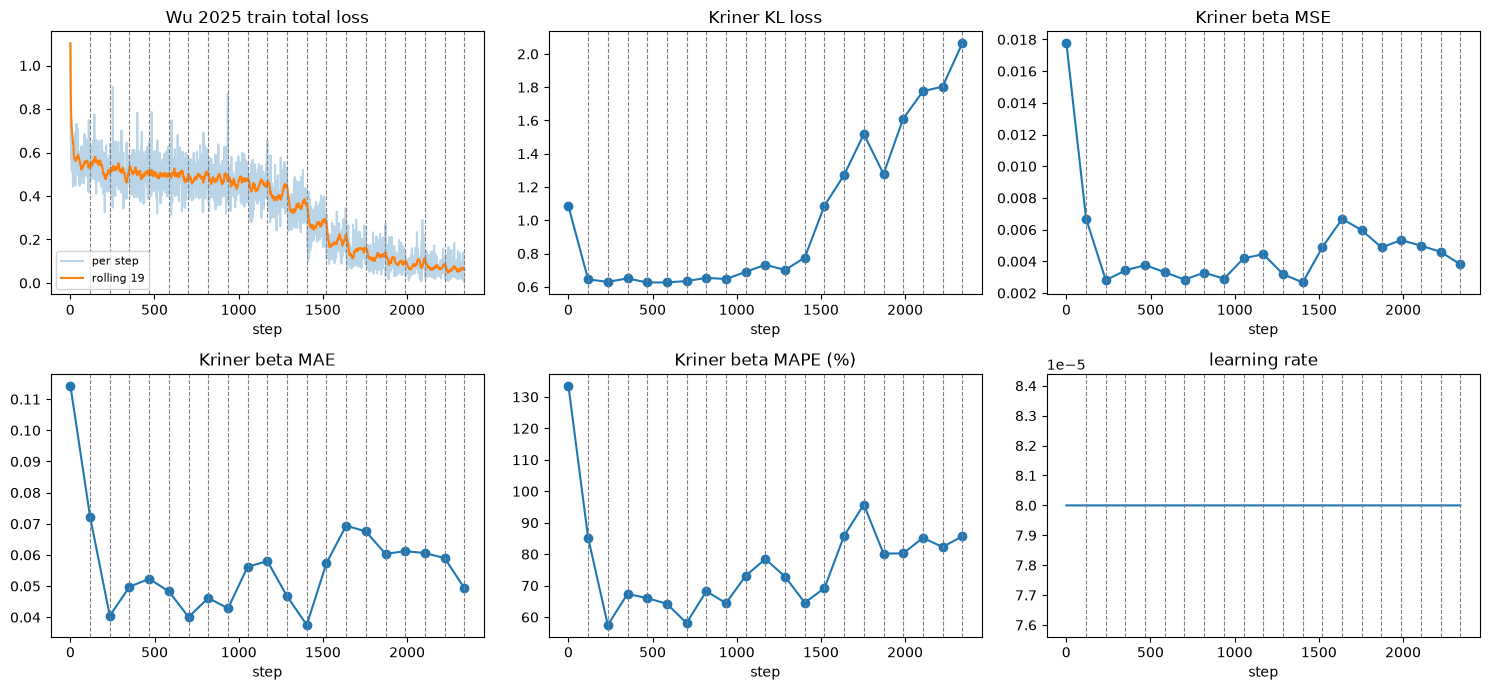

S=16 | lambda=0:   0%|          | 0/2340 [00:00<?, ?it/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

... (11 outputs left out)

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

In [12]:
# Overfit check: many passes over all Wu 2025 respondents with pure KL/CE, constant LR, and no weight decay
OVERFIT_SAMPLE_SIZE = 16
OVERFIT_NUM_EPOCHS = 20
OVERFIT_LR = scale_lr_for_sample_size(OVERFIT_SAMPLE_SIZE)
OVERFIT_EVAL_EVERY = math.ceil(len(wu2025_respondent_items) / OVERFIT_SAMPLE_SIZE)  # one Kriner eval per epoch
OVERFIT_MICRO_CHUNK = 4                       # respondents per forward/backward chunk (sets peak VRAM)
OVERFIT_GRADIENT_CHECKPOINTING = False

overfit_run = run_wu2025_epoch(
    sample_size=OVERFIT_SAMPLE_SIZE,
    beta_lambda=0.0,
    lr=OVERFIT_LR,
    num_epochs=OVERFIT_NUM_EPOCHS,
    eval_every=OVERFIT_EVAL_EVERY,
    lr_schedule="constant",
    weight_decay=0.0,
    micro_chunk=OVERFIT_MICRO_CHUNK,
    gradient_checkpointing=OVERFIT_GRADIENT_CHECKPOINTING,
)


# Train

In [13]:
_ = validate_kriner2026_population_ols(
                kev_model,
                kriner2026_eval_bundle,
                A_kriner_pop,
                y_kriner_pop,
                kriner_human_betas,
                KRINER_BETA_NAMES,
            )

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

In [15]:
# Number of human respondents sampled per optimization step (edit `SAMPLE_SIZE` here to run 8, 16, 32, etc.)
SAMPLE_SIZE = 16
# Number of full passes over all Wu 2025 respondents per run
NUM_EPOCHS = 5
# Optimization steps between Kriner 2026 validations (a final validation always runs at the last step)
EVAL_EVERY = 29
# Learning-rate schedule ("onecycle" or "constant") and AdamW weight decay for the lambda runs
LR_SCHEDULE = "onecycle"
WEIGHT_DECAY = 0.01
# Respondents per forward/backward micro-chunk (sets peak VRAM; gradients equal one full-sample backward)
MICRO_CHUNK = 4
GRADIENT_CHECKPOINTING = False
SAMPLE_LR = scale_lr_for_sample_size(SAMPLE_SIZE)
steps_per_epoch = math.ceil(len(wu2025_respondent_items) / SAMPLE_SIZE)
total_wu_option_rows = sum(int(it["X_resp"].shape[0]) for it in wu2025_respondent_items)

display(
    pd.Series(
        {
            "sample_size": SAMPLE_SIZE,
            "num_epochs": NUM_EPOCHS,
            "steps_per_epoch": steps_per_epoch,
            "total_steps": steps_per_epoch * NUM_EPOCHS,
            "eval_every": EVAL_EVERY,
            "lr_schedule": LR_SCHEDULE,
            "weight_decay": WEIGHT_DECAY,
            "mean_option_rows_per_step": round(total_wu_option_rows / steps_per_epoch, 2),
            "scaled_max_lr": SAMPLE_LR,
            "micro_chunk": MICRO_CHUNK,
            "gradient_checkpointing": GRADIENT_CHECKPOINTING,
        },
        name="selected_sample_size_config",
    ).to_frame()
)

,selected_sample_size_config
sample_size,16
num_epochs,5
steps_per_epoch,117
total_steps,585
eval_every,29
lr_schedule,onecycle
weight_decay,0.01
mean_option_rows_per_step,317.79
scaled_max_lr,0.00008
micro_chunk,4


,epoch,respondents_seen,train_loss,kriner_kl_loss,kriner_beta_mse,kriner_beta_mae,kriner_beta_mape_pct,spearman_rho,lr,eval_prep_sec,eval_gpu_sec,eval_ols_ms,eval_wall_sec,eval_ms_per_task,train_elapsed_sec
step,,,,,,,,,,,,,,,
0,0,0,NaN,1.08491,0.01776,0.11429,133.52860,-0.26573,NaN,0.04291,8.81824,1.60339,10.53489,2.10698,0.00000
29,1,464,0.61490,0.67434,0.00749,0.07584,89.78413,0.54545,0.00004,0.00361,8.19176,1.80701,9.21565,1.84313,59.07550
58,1,928,0.57359,0.62517,0.00388,0.05407,69.89290,0.86014,0.00008,0.00391,8.28016,1.79152,9.36160,1.87232,117.48324
87,1,1392,0.56270,0.65600,0.01005,0.08049,86.00184,0.93706,0.00008,0.00370,8.21893,2.23100,9.33123,1.86625,177.82927
116,1,1856,0.56820,0.63360,0.00414,0.05559,75.67206,0.69231,0.00008,0.00553,10.12261,2.96028,11.65378,2.33076,246.80267
145,2,2309,0.56640,0.62368,0.00328,0.04723,66.91000,0.81818,0.00007,0.00418,10.41511,2.31422,11.94464,2.38893,313.40697
174,2,2773,0.55174,0.63509,0.00481,0.06094,78.16780,0.65035,0.00007,0.00446,10.45046,2.17441,11.98999,2.39800,389.14118
203,2,3237,0.50425,0.63273,0.00304,0.04348,64.27310,0.86713,0.00007,0.00462,10.24144,1.99329,11.77618,2.35524,463.29697
232,2,3701,0.51199,0.63353,0.00451,0.05882,73.42812,0.90909,0.00006,0.00392,9.10592,2.23690,10.56187,2.11237,535.54115


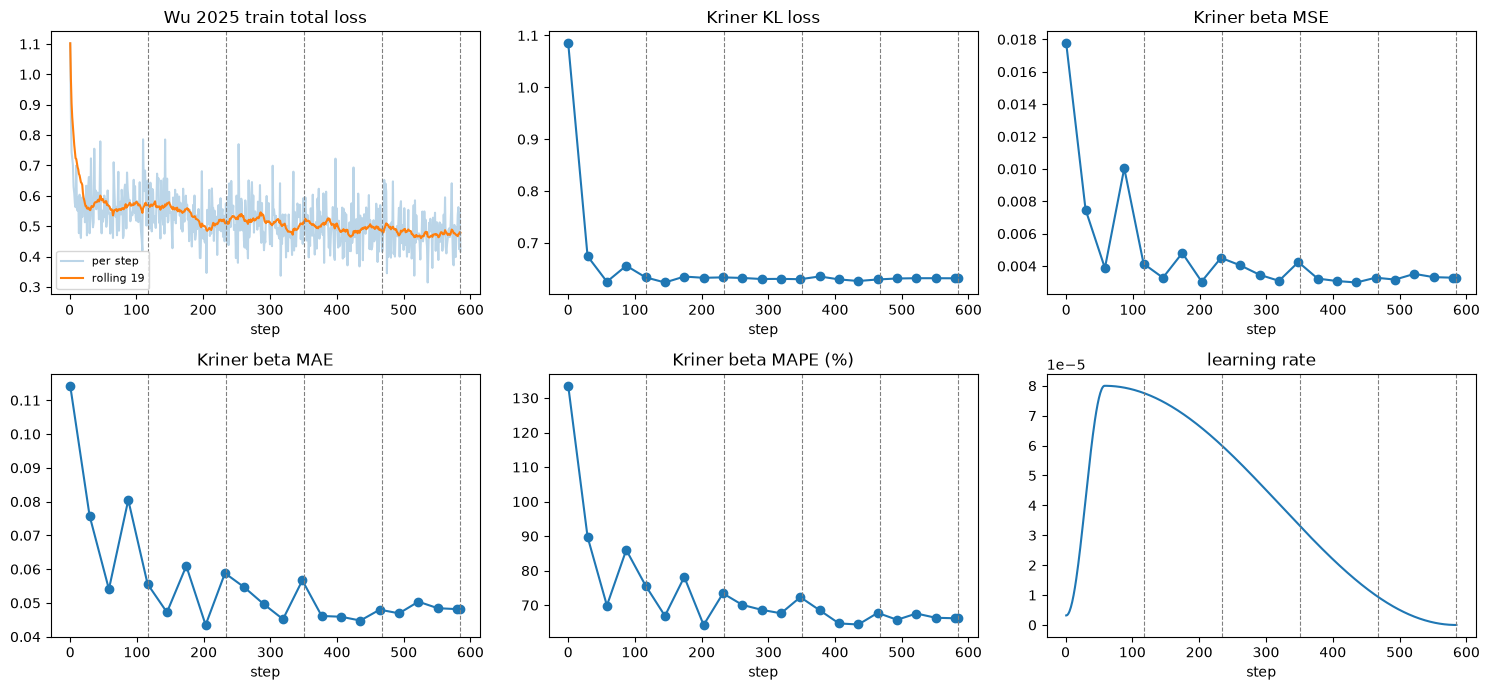

S=16 | lambda=0:   0%|          | 0/585 [00:00<?, ?it/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

In [16]:
# Run `NUM_EPOCHS` epochs at `SAMPLE_SIZE` respondents/step with `beta_lambda = 0.0` (pure per-response KL/CE baseline)
experiment_runs[(SAMPLE_SIZE, 0.0)] = run_wu2025_epoch(
    sample_size=SAMPLE_SIZE,
    beta_lambda=0.0,
    lr=SAMPLE_LR,
    num_epochs=NUM_EPOCHS,
    eval_every=EVAL_EVERY,
    lr_schedule=LR_SCHEDULE,
    weight_decay=WEIGHT_DECAY,
    micro_chunk=MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
)

,epoch,respondents_seen,train_loss,kriner_kl_loss,kriner_beta_mse,kriner_beta_mae,kriner_beta_mape_pct,spearman_rho,lr,eval_prep_sec,eval_gpu_sec,eval_ols_ms,eval_wall_sec,eval_ms_per_task,train_elapsed_sec
step,,,,,,,,,,,,,,,
0,0,0,NaN,1.08491,0.01776,0.11429,133.52860,-0.26573,NaN,0.04291,8.81824,1.60339,10.53489,2.10698,0.00000
29,1,464,0.62908,0.67622,0.00753,0.07595,89.69822,0.54545,0.00004,0.00349,7.84169,1.80354,8.83716,1.76743,55.18518
58,1,928,0.58805,0.62461,0.00349,0.05132,68.81804,0.86014,0.00008,0.00343,7.84819,1.73190,8.83322,1.76664,110.46052
87,1,1392,0.57268,0.66143,0.01123,0.08340,86.93415,0.91608,0.00008,0.00344,7.84780,1.76621,8.82604,1.76521,165.64647
116,1,1856,0.57548,0.64933,0.00783,0.07475,83.27958,0.84615,0.00008,0.00340,7.84487,1.75142,8.81888,1.76378,220.59183
145,2,2309,0.57992,0.62333,0.00378,0.05252,66.69578,0.84615,0.00007,0.00351,7.84594,1.73801,8.83209,1.76642,274.61624
174,2,2773,0.56068,0.63238,0.00497,0.06132,75.30642,0.85315,0.00007,0.00347,7.84491,1.78879,8.82912,1.76582,329.83206
203,2,3237,0.51409,0.63064,0.00275,0.03986,57.14799,0.86014,0.00007,0.00344,7.84451,1.79628,8.83185,1.76637,384.83709
232,2,3701,0.51547,0.62773,0.00406,0.05502,69.06081,0.86014,0.00006,0.00345,7.84432,1.78380,8.83179,1.76636,439.97582


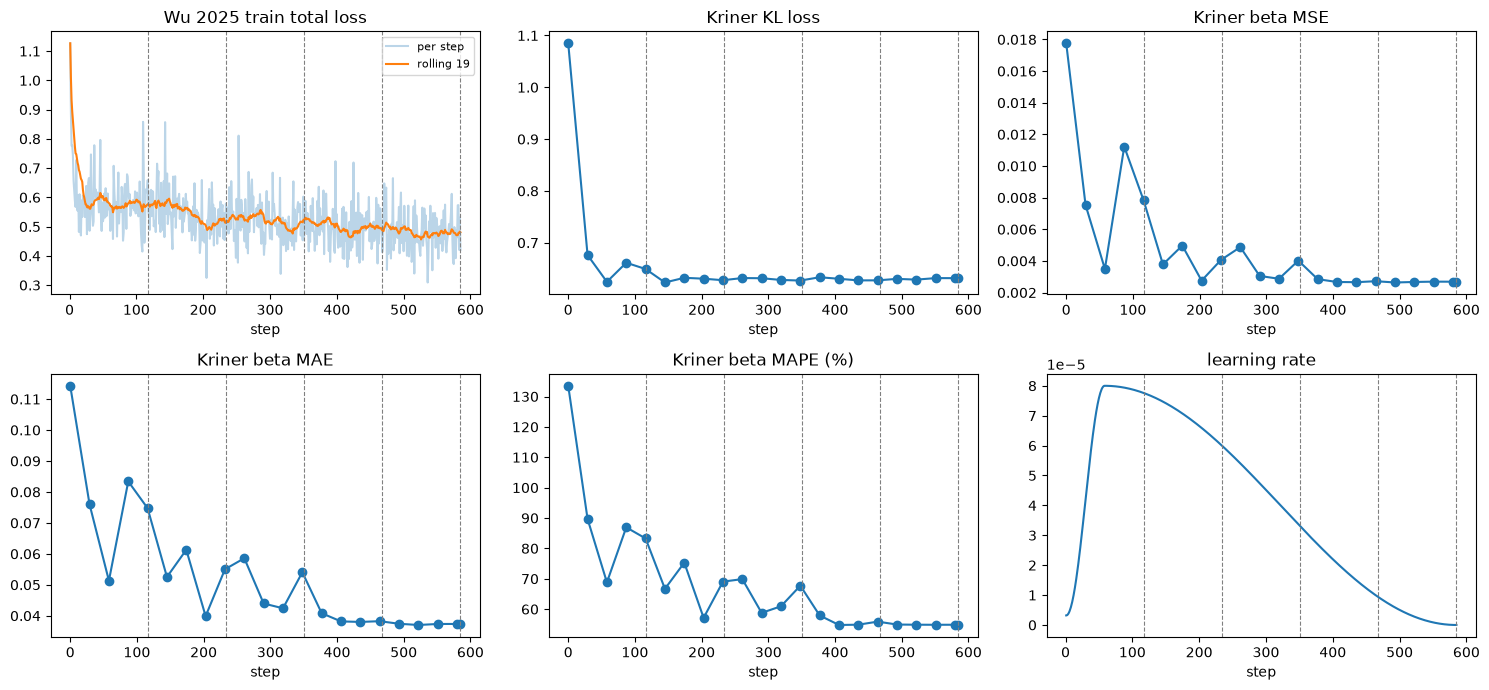

S=16 | lambda=1:   0%|          | 0/585 [00:00<?, ?it/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

In [17]:
# Run `NUM_EPOCHS` epochs at `SAMPLE_SIZE` respondents/step with `beta_lambda = 1.0` (mild sample OLS beta weight)
experiment_runs[(SAMPLE_SIZE, 1.0)] = run_wu2025_epoch(
    sample_size=SAMPLE_SIZE,
    beta_lambda=1.0,
    lr=SAMPLE_LR,
    num_epochs=NUM_EPOCHS,
    eval_every=EVAL_EVERY,
    lr_schedule=LR_SCHEDULE,
    weight_decay=WEIGHT_DECAY,
    micro_chunk=MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
)

,epoch,respondents_seen,train_loss,kriner_kl_loss,kriner_beta_mse,kriner_beta_mae,kriner_beta_mape_pct,spearman_rho,lr,eval_prep_sec,eval_gpu_sec,eval_ols_ms,eval_wall_sec,eval_ms_per_task,train_elapsed_sec
step,,,,,,,,,,,,,,,
0,0,0,NaN,1.08491,0.01776,0.11429,133.52860,-0.26573,NaN,0.04291,8.81824,1.60339,10.53489,2.10698,0.00000
29,1,464,0.64312,0.67771,0.00738,0.07528,89.03547,0.56643,0.00004,0.00352,8.57396,1.83328,9.66217,1.93243,61.02124
58,1,928,0.60029,0.62251,0.00325,0.04859,66.62900,0.83916,0.00008,0.00358,8.59671,1.83378,9.70648,1.94130,120.96532
87,1,1392,0.57982,0.64585,0.00725,0.07090,79.98702,0.90210,0.00008,0.00408,8.65982,1.82687,9.84397,1.96879,181.26007
116,1,1856,0.58052,0.63014,0.00410,0.05550,73.27883,0.86014,0.00008,0.00363,8.21362,1.85485,9.28264,1.85653,240.64780
145,2,2309,0.59392,0.61929,0.00294,0.04393,63.22745,0.90210,0.00007,0.00379,8.38270,1.84858,9.53946,1.90789,297.87535
174,2,2773,0.57445,0.62992,0.00458,0.05855,73.26100,0.86014,0.00007,0.00432,8.59442,1.90757,9.69431,1.93886,357.95322
203,2,3237,0.52126,0.63140,0.00272,0.04022,61.58419,0.86014,0.00007,0.00421,8.51008,1.87663,9.63852,1.92770,419.86546
232,2,3701,0.52442,0.62607,0.00368,0.05109,66.22736,0.86014,0.00006,0.00454,10.17940,2.76974,11.80362,2.36072,493.72585


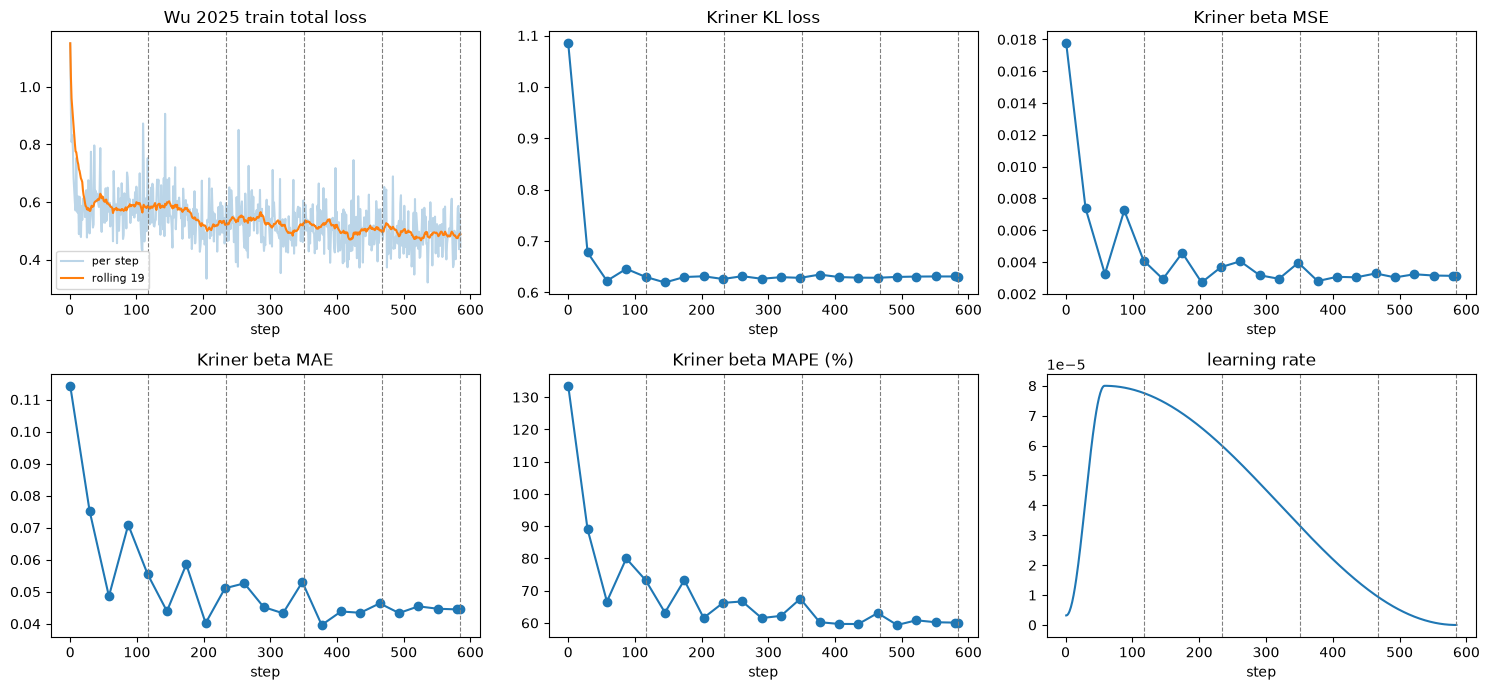

S=16 | lambda=2:   0%|          | 0/585 [00:00<?, ?it/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

In [18]:
beta_lambda = 2.0
experiment_runs[(SAMPLE_SIZE, beta_lambda)] = run_wu2025_epoch(
    sample_size=SAMPLE_SIZE,
    beta_lambda=beta_lambda,
    lr=SAMPLE_LR,
    num_epochs=NUM_EPOCHS,
    eval_every=EVAL_EVERY,
    lr_schedule=LR_SCHEDULE,
    weight_decay=WEIGHT_DECAY,
    micro_chunk=MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
)

,epoch,respondents_seen,train_loss,kriner_kl_loss,kriner_beta_mse,kriner_beta_mae,kriner_beta_mape_pct,spearman_rho,lr,eval_prep_sec,eval_gpu_sec,eval_ols_ms,eval_wall_sec,eval_ms_per_task,train_elapsed_sec
step,,,,,,,,,,,,,,,
0,0,0,NaN,1.08491,0.01776,0.11429,133.52860,-0.26573,NaN,0.04291,8.81824,1.60339,10.53489,2.10698,0.00000
29,1,464,0.65696,0.67883,0.00725,0.07467,88.56903,0.63636,0.00004,0.00359,8.35067,1.87507,9.44745,1.88949,68.66976
58,1,928,0.61191,0.62278,0.00320,0.04770,65.88876,0.83916,0.00008,0.00410,10.40197,2.13591,11.98593,2.39719,137.34102
87,1,1392,0.59247,0.64933,0.00778,0.07321,81.53664,0.90210,0.00008,0.00448,10.55936,2.03880,12.19118,2.43824,211.15751
116,1,1856,0.59052,0.63119,0.00396,0.05395,70.71596,0.83916,0.00008,0.00431,10.56004,2.09577,12.17499,2.43500,284.31978
145,2,2309,0.60187,0.62011,0.00298,0.04372,62.31511,0.86014,0.00007,0.00360,8.59529,1.86279,9.67906,1.93581,347.49386
174,2,2773,0.57727,0.63089,0.00417,0.05603,71.83862,0.90909,0.00007,0.00365,8.38988,1.88299,9.44904,1.88981,408.40382
203,2,3237,0.53082,0.62763,0.00270,0.03890,56.45486,0.86014,0.00007,0.00655,10.35163,2.07172,11.97677,2.39535,482.25394
232,2,3701,0.53053,0.62375,0.00305,0.04396,61.37450,0.86014,0.00006,0.00432,10.60422,3.59466,12.22868,2.44574,557.93522


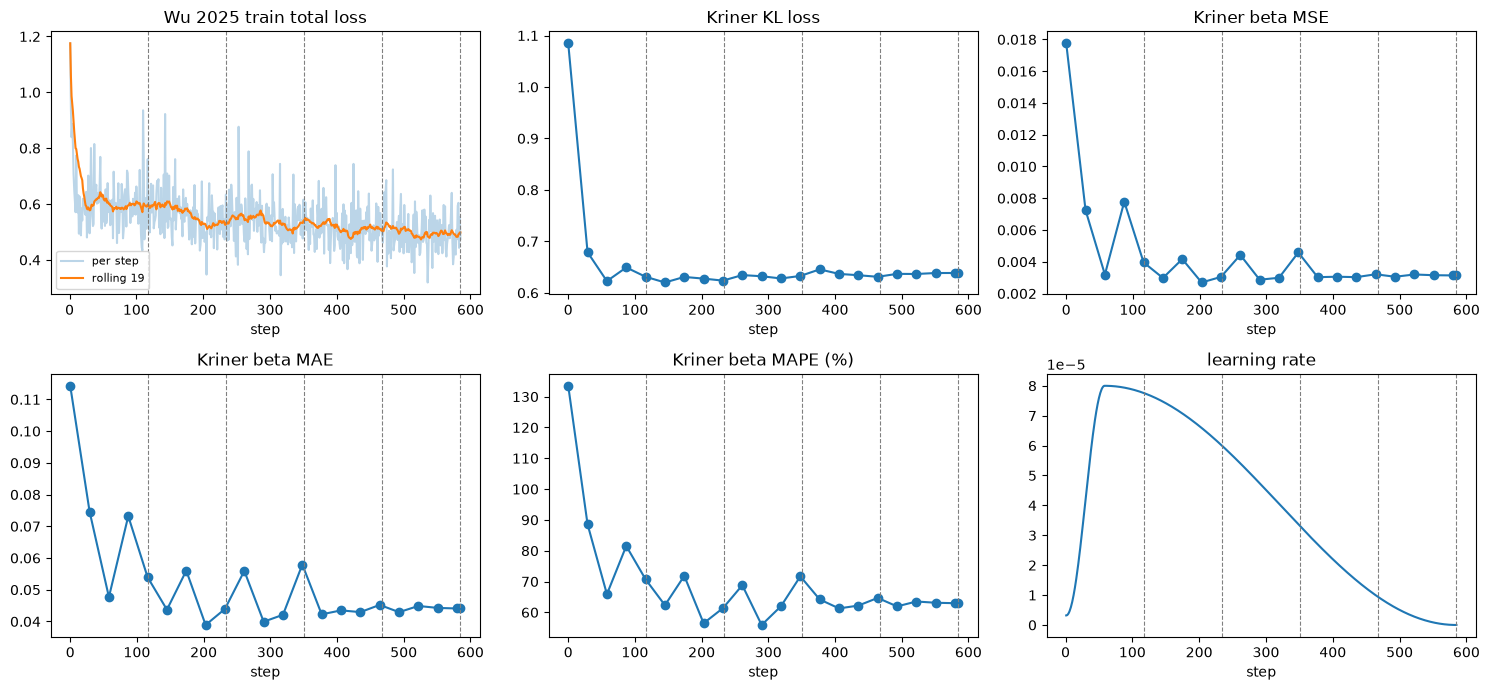

S=16 | lambda=3:   0%|          | 0/585 [00:00<?, ?it/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

In [19]:
beta_lambda = 3.0
experiment_runs[(SAMPLE_SIZE, beta_lambda)] = run_wu2025_epoch(
    sample_size=SAMPLE_SIZE,
    beta_lambda=beta_lambda,
    lr=SAMPLE_LR,
    num_epochs=NUM_EPOCHS,
    eval_every=EVAL_EVERY,
    lr_schedule=LR_SCHEDULE,
    weight_decay=WEIGHT_DECAY,
    micro_chunk=MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
)

,epoch,respondents_seen,train_loss,kriner_kl_loss,kriner_beta_mse,kriner_beta_mae,kriner_beta_mape_pct,spearman_rho,lr,eval_prep_sec,eval_gpu_sec,eval_ols_ms,eval_wall_sec,eval_ms_per_task,train_elapsed_sec
step,,,,,,,,,,,,,,,
0,0,0,NaN,1.08491,0.01776,0.11429,133.52860,-0.26573,NaN,0.04291,8.81824,1.60339,10.53489,2.10698,0.00000
29,1,464,0.67155,0.68482,0.00732,0.07511,89.00648,0.54545,0.00004,0.00381,8.33739,1.82480,9.37504,1.87501,59.53116
58,1,928,0.62475,0.62187,0.00313,0.04691,64.72964,0.83916,0.00008,0.00382,9.18447,2.17977,10.46254,2.09251,119.05187
87,1,1392,0.60509,0.64694,0.00769,0.07328,82.69552,0.90210,0.00008,0.00347,8.09309,1.82645,9.08883,1.81777,178.47913
116,1,1856,0.60599,0.62829,0.00406,0.05488,71.60411,0.90210,0.00008,0.00354,8.28742,1.83632,9.32868,1.86574,236.77369
145,2,2309,0.61509,0.62368,0.00352,0.05066,67.68733,0.90909,0.00007,0.00355,8.28418,1.79712,9.34281,1.86856,294.93047
174,2,2773,0.58554,0.63008,0.00397,0.05447,72.96712,0.90909,0.00007,0.00358,8.67913,1.87791,9.79406,1.95881,354.46493
203,2,3237,0.53811,0.62800,0.00263,0.04164,61.00213,0.90210,0.00007,0.00364,8.20499,1.84560,9.29738,1.85948,413.78397
232,2,3701,0.54260,0.62150,0.00308,0.04537,64.06881,0.90210,0.00006,0.00381,8.15864,1.95764,9.22935,1.84587,472.04144


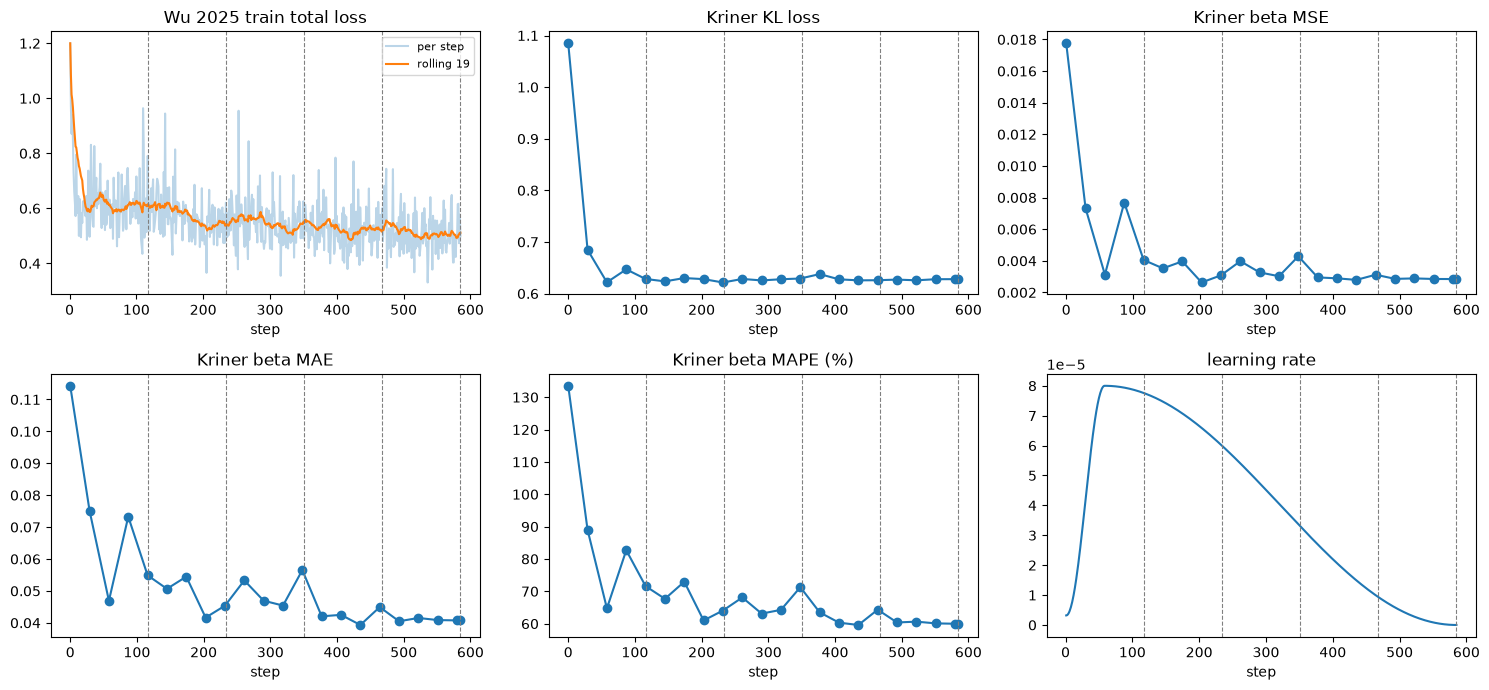

S=16 | lambda=4:   0%|          | 0/585 [00:00<?, ?it/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

In [20]:
beta_lambda = 4.0
experiment_runs[(SAMPLE_SIZE, beta_lambda)] = run_wu2025_epoch(
    sample_size=SAMPLE_SIZE,
    beta_lambda=beta_lambda,
    lr=SAMPLE_LR,
    num_epochs=NUM_EPOCHS,
    eval_every=EVAL_EVERY,
    lr_schedule=LR_SCHEDULE,
    weight_decay=WEIGHT_DECAY,
    micro_chunk=MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
)

,epoch,respondents_seen,train_loss,kriner_kl_loss,kriner_beta_mse,kriner_beta_mae,kriner_beta_mape_pct,spearman_rho,lr,eval_prep_sec,eval_gpu_sec,eval_ols_ms,eval_wall_sec,eval_ms_per_task,train_elapsed_sec
step,,,,,,,,,,,,,,,
0,0,0,NaN,1.08491,0.01776,0.11429,133.52860,-0.26573,NaN,0.04291,8.81824,1.60339,10.53489,2.10698,0.00000
29,1,464,0.68610,0.68939,0.00717,0.07442,88.41575,0.56643,0.00004,0.00340,8.04895,1.84598,9.01628,1.80326,59.20828
58,1,928,0.63765,0.62323,0.00302,0.04513,63.68801,0.83916,0.00008,0.00331,8.07018,1.85400,9.12162,1.82432,116.64969
87,1,1392,0.61237,0.64765,0.00831,0.07628,86.14346,0.89510,0.00008,0.00342,8.62669,1.80185,9.65120,1.93024,175.48488
116,1,1856,0.61253,0.63304,0.00411,0.05498,72.22951,0.86713,0.00008,0.00357,8.07491,1.82384,9.14474,1.82895,233.20088
145,2,2309,0.64140,0.62747,0.00417,0.05584,71.84964,0.90210,0.00007,0.00357,8.14009,1.83529,9.24272,1.84854,289.35557
174,2,2773,0.59836,0.63924,0.00465,0.05991,77.16030,0.86713,0.00007,0.00349,7.94671,1.80328,8.97583,1.79517,346.09099
203,2,3237,0.55032,0.62660,0.00278,0.04072,63.07250,0.90210,0.00007,0.00336,7.87172,1.79945,8.88208,1.77642,402.29589
232,2,3701,0.55341,0.62958,0.00301,0.04306,64.65119,0.83916,0.00006,0.00337,7.86577,1.85602,8.86128,1.77226,458.25586


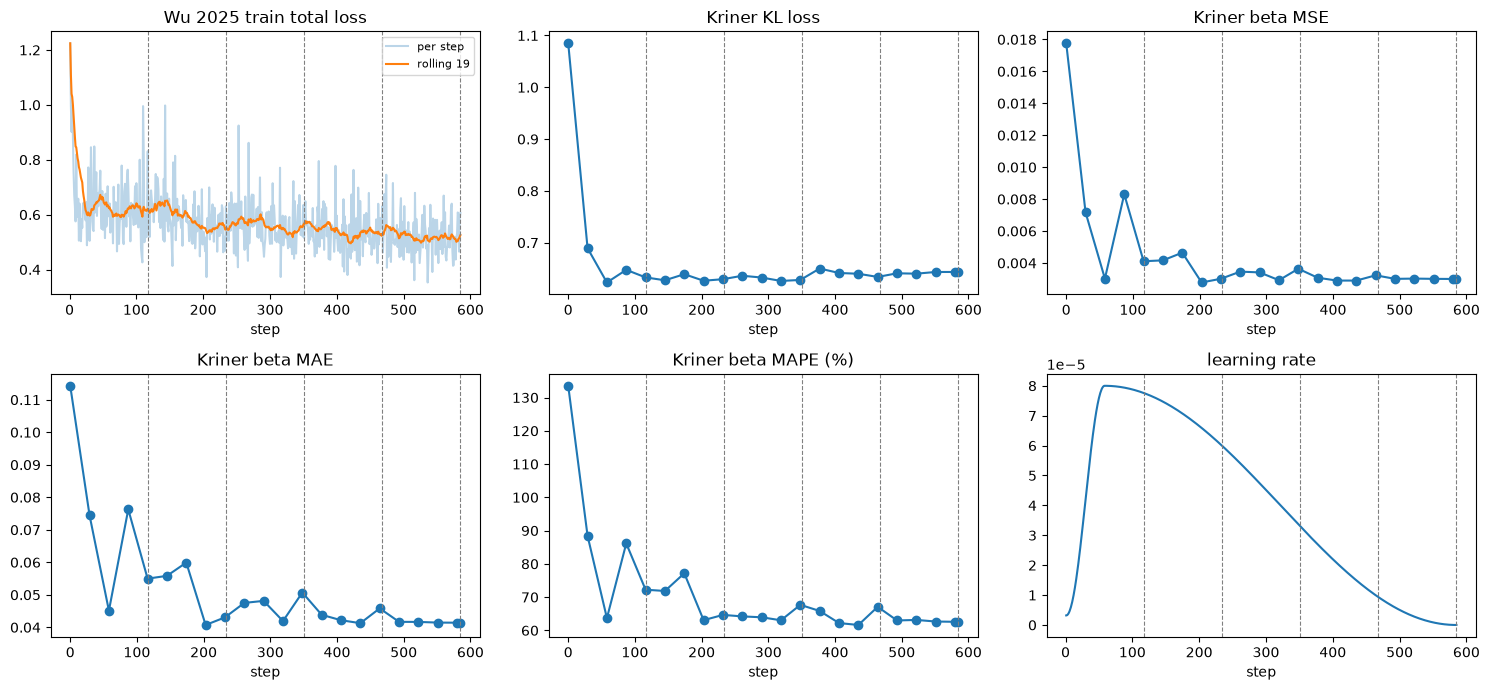

S=16 | lambda=5:   0%|          | 0/585 [00:00<?, ?it/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

In [21]:
# Run `NUM_EPOCHS` epochs at `SAMPLE_SIZE` respondents/step with `beta_lambda = 5.0` (moderate sample OLS beta weight)
experiment_runs[(SAMPLE_SIZE, 5.0)] = run_wu2025_epoch(
    sample_size=SAMPLE_SIZE,
    beta_lambda=5.0,
    lr=SAMPLE_LR,
    num_epochs=NUM_EPOCHS,
    eval_every=EVAL_EVERY,
    lr_schedule=LR_SCHEDULE,
    weight_decay=WEIGHT_DECAY,
    micro_chunk=MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
)

,epoch,respondents_seen,train_loss,kriner_kl_loss,kriner_beta_mse,kriner_beta_mae,kriner_beta_mape_pct,spearman_rho,lr,eval_prep_sec,eval_gpu_sec,eval_ols_ms,eval_wall_sec,eval_ms_per_task,train_elapsed_sec
step,,,,,,,,,,,,,,,
0,0,0,NaN,1.08491,0.01776,0.11429,133.52860,-0.26573,NaN,0.04291,8.81824,1.60339,10.53489,2.10698,0.00000
29,1,464,0.90067,0.66921,0.00656,0.07187,87.80220,0.52448,0.00004,0.00354,8.34090,1.93024,9.45312,1.89062,58.79200
58,1,928,0.88143,0.63446,0.00319,0.04707,70.09531,0.83916,0.00008,0.00353,8.20884,1.87038,9.30422,1.86084,117.70849
87,1,1392,0.76087,0.64881,0.00850,0.07551,83.67826,0.94406,0.00008,0.00390,8.37917,1.90020,9.48534,1.89707,176.05653
116,1,1856,0.77837,0.63774,0.00585,0.06672,80.23961,0.91608,0.00008,0.00392,8.15047,1.87086,9.18208,1.83642,234.77334
145,2,2309,0.87073,0.62319,0.00380,0.05289,67.58805,0.92308,0.00007,0.00338,8.09177,1.81077,9.13062,1.82612,291.87075
174,2,2773,0.75154,0.62490,0.00329,0.04741,68.70014,0.92308,0.00007,0.00361,8.66313,1.85083,9.74921,1.94984,353.51487
203,2,3237,0.68195,0.62238,0.00293,0.04288,63.94112,0.92308,0.00007,0.00358,8.51951,1.99072,9.54252,1.90850,412.54709
232,2,3701,0.69903,0.62658,0.00356,0.05047,68.63134,0.92308,0.00006,0.00387,8.52660,1.89828,9.61603,1.92321,471.08094


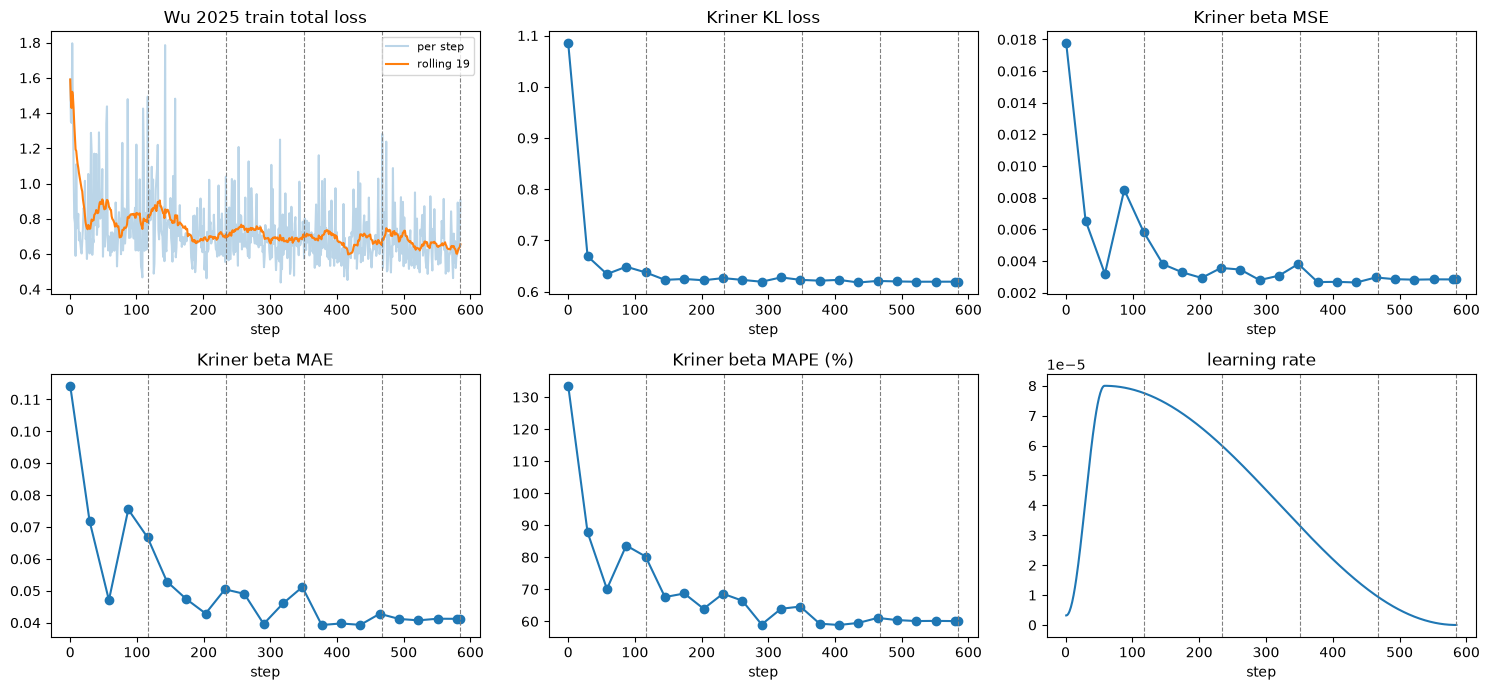

S=16 | lambda=20:   0%|          | 0/585 [00:00<?, ?it/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

Evaluating kriner2026_flight_choice (shared-state):   0%|          | 0/22 [00:00<?, ?batch/s]

In [22]:
# Run `NUM_EPOCHS` epochs at `SAMPLE_SIZE` respondents/step with `beta_lambda = 20.0` (strong sample OLS beta weight)
experiment_runs[(SAMPLE_SIZE, 20.0)] = run_wu2025_epoch(
    sample_size=SAMPLE_SIZE,
    beta_lambda=20.0,
    lr=SAMPLE_LR,
    num_epochs=NUM_EPOCHS,
    eval_every=EVAL_EVERY,
    lr_schedule=LR_SCHEDULE,
    weight_decay=WEIGHT_DECAY,
    micro_chunk=MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
)

In [23]:
# Compare Wu 2025 train metrics, held-out Kriner 2026 OLS/KL metrics, and timing metrics across completed runs
if not experiment_runs:
    raise ValueError("Run at least one `run_wu2025_epoch` cell first so `experiment_runs` is populated")
ran_keys = sorted(experiment_runs.keys())

compare_rows = [
    {
        "run": "step_0 (untrained)",
        "sample_size": 0,
        "beta_lambda": float("nan"),
        "num_epochs": 0,
        "steps_per_epoch": 0,
        "train_kl_last15pct": float("nan"),
        "train_raw_beta_last15pct": float("nan"),
        "kriner_kl_loss": step0_val_metrics["kriner_kl_loss"],
        "kriner_beta_mse": step0_val_metrics["kriner_beta_mse"],
        "kriner_beta_mae": step0_val_metrics["kriner_beta_mae"],
        "kriner_beta_mape_pct": step0_val_metrics["kriner_beta_mape_pct"],
        "spearman_rho": step0_val_metrics["spearman_rho"],
        "mean_step_ms": float("nan"),
        "mean_ms_per_respondent": float("nan"),
        "mean_eval_wall_sec": step0_val_metrics["eval_wall_sec"],
        "train_only_sec": 0.0,
        "eval_only_sec": step0_val_metrics["eval_wall_sec"],
        "total_wall_sec": step0_val_metrics["eval_wall_sec"],
    }
]
for s_size, lam in ran_keys:
    run = experiment_runs[(s_size, lam)]
    s = run["summary"]
    final_val = run["val_history_df"].iloc[-1]
    compare_rows.append(
        {
            "run": f"S={s_size}, lambda={lam:g}",
            "sample_size": s_size,
            "beta_lambda": lam,
            "num_epochs": int(s["num_epochs"]),
            "steps_per_epoch": int(s["steps_per_epoch"]),
            "train_kl_last15pct": float(s["train_kl_last15pct"]),
            "train_raw_beta_last15pct": float(s["train_raw_beta_last15pct"]),
            "kriner_kl_loss": float(final_val["kriner_kl_loss"]),
            "kriner_beta_mse": float(final_val["kriner_beta_mse"]),
            "kriner_beta_mae": float(final_val["kriner_beta_mae"]),
            "kriner_beta_mape_pct": float(final_val["kriner_beta_mape_pct"]),
            "spearman_rho": float(final_val["spearman_rho"]),
            "mean_step_ms": float(s["mean_step_ms"]),
            "mean_ms_per_respondent": float(s["mean_ms_per_respondent"]),
            "mean_eval_wall_sec": float(s["mean_eval_wall_sec"]),
            "train_only_sec": float(s["train_only_sec"]),
            "eval_only_sec": float(s["eval_only_sec"]),
            "total_wall_sec": float(s["total_wall_sec"]),
        }
    )

comparison_df = pd.DataFrame(compare_rows).set_index("run")
display(comparison_df.round(5))

# Compare the 12 predicted Kriner 2026 Table-2 AMCE betas against the ground-truth human Table-2 betas
kriner_betas_compare_df = pd.DataFrame(
    {
        "human_pop_beta": step0_beta_df["human_pop_beta"],
        "step_0": step0_beta_df["model_pop_beta"],
        **{
            f"S={s_size}, lambda={lam:g}": experiment_runs[(s_size, lam)]["final_beta_df"]["model_pop_beta"]
            for s_size, lam in ran_keys
        },
    }
)
display(kriner_betas_compare_df.round(4))

,sample_size,beta_lambda,num_epochs,steps_per_epoch,train_kl_last15pct,train_raw_beta_last15pct,kriner_kl_loss,kriner_beta_mse,kriner_beta_mae,kriner_beta_mape_pct,spearman_rho,mean_step_ms,mean_ms_per_respondent,mean_eval_wall_sec,train_only_sec,eval_only_sec,total_wall_sec
run,,,,,,,,,,,,,,,,,
step_0 (untrained),0,NaN,0,0,NaN,NaN,1.08491,0.01776,0.11429,133.52860,-0.26573,NaN,NaN,10.53489,0.00000,10.53489,10.53489
"S=16, lambda=0",16,0.0,5,117,0.47262,0.00592,0.63174,0.00328,0.04815,66.17082,0.86713,2107.49813,132.49720,9.78395,1232.88641,205.46296,1565.04562
"S=16, lambda=1",16,1.0,5,117,0.46894,0.00575,0.63168,0.00268,0.03734,54.82341,0.83916,1932.18963,121.47565,9.05548,1130.33093,190.16509,1444.99117
"S=16, lambda=2",16,2.0,5,117,0.47318,0.00584,0.63091,0.00314,0.04450,60.13796,0.83217,2340.73292,147.16053,10.87851,1369.32876,228.44868,1732.59702
"S=16, lambda=3",16,3.0,5,117,0.47424,0.00586,0.63858,0.00314,0.04412,63.04855,0.83916,2259.91549,142.07959,10.40541,1322.05056,218.51357,1671.80987
"S=16, lambda=4",16,4.0,5,117,0.48053,0.00608,0.62787,0.00285,0.04074,59.93060,0.83217,1986.28464,124.87657,9.26030,1161.97652,194.46628,1480.75314
"S=16, lambda=5",16,5.0,5,117,0.48538,0.00614,0.64363,0.00300,0.04143,62.55545,0.84615,1966.20086,123.61392,9.15610,1150.22750,192.27809,1465.36871
"S=16, lambda=20",16,20.0,5,117,0.51253,0.00695,0.61955,0.00284,0.04119,60.03223,0.92308,1991.82367,125.22481,9.30273,1165.21685,195.35724,1487.28493


,human_pop_beta,step_0,"S=16, lambda=0","S=16, lambda=1","S=16, lambda=2","S=16, lambda=3","S=16, lambda=4","S=16, lambda=5","S=16, lambda=20"
kriner_term,,,,,,,,,
Airline: Frontier,-0.0854,0.0344,-0.0110,-0.0166,-0.0139,-0.0136,-0.0129,-0.0100,-0.0125
Airline: Southwest,-0.0238,0.0267,-0.0072,-0.0063,-0.0050,-0.0037,-0.0069,-0.0023,-0.0069
Airline: United,-0.0220,0.0010,0.0059,0.0052,0.0034,0.0077,0.0050,0.0089,0.0057
Fuel: Sustainable aviation fuel,0.0691,-0.0574,0.0431,0.0684,0.0462,0.0514,0.0450,0.0600,0.0266
Baggage: Checked bag+carry-on,0.0561,-0.0435,-0.0018,-0.0056,-0.0017,-0.0019,-0.0011,-0.0049,-0.0007
Baggage: Personal item only,-0.1393,-0.0030,-0.0239,-0.0325,-0.0216,-0.0197,-0.0234,-0.0214,-0.0195
Space: Extra legroom,0.0653,-0.0813,0.0186,0.0677,0.0579,0.0434,0.0482,0.0370,0.0595
Seat: Middle,-0.0906,-0.0057,0.0007,0.0100,0.0040,0.0104,0.0053,0.0049,-0.0083
Seat: Window,0.0384,0.0086,0.0107,0.0211,0.0121,0.0136,0.0134,0.0152,0.0120
